In [4]:
import pandas as pd
import numpy as np
from scipy.optimize import minimize_scalar
from scipy.stats import kendalltau, spearmanr, multivariate_normal, norm, chi2, kruskal, ranksums, bootstrap, permutation_test, pearsonr
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity
from factor_analyzer import FactorAnalyzer
from factor_analyzer.rotator import Rotator
from sklearn.decomposition import PCA
from itertools import combinations
from statsmodels.stats.correlation_tools import corr_nearest
import matplotlib.pyplot as plt
import warnings
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
import pingouin as pg
import plotly.express as px
import plotly.graph_objects as go
import json
import subprocess
import tempfile
import os
from sklearn.svm import SVC

# Suppress minor convergence warnings during bootstrap iterations
warnings.filterwarnings("ignore")

In [5]:
def evaluate_kmo_bartlett_factorability(
    df: pd.DataFrame = None,
    corr_matrix: pd.DataFrame = None,
    n_bootstraps: int = 1000,
    ci_level: float = 0.95,
    random_state: int = 42,
) -> dict:
    """Computes overall and per-item KMO and Bartlett's Test of Sphericity

    with regularized small-sample bootstrap confidence intervals.
    """
    rng = np.random.default_rng(random_state)

    if df is not None:
        clean_df = df.apply(pd.to_numeric, errors="coerce").dropna().astype(float)
        cols = list(clean_df.columns)
        n_obs, n_vars = clean_df.shape
        data_arr = clean_df.to_numpy()
        input_data = clean_df if corr_matrix is None else corr_matrix.copy()
        is_corr = corr_matrix is not None
    elif corr_matrix is not None:
        input_data = corr_matrix.copy()
        cols = list(corr_matrix.columns)
        n_obs = 27
        n_vars = len(cols)
        data_arr = None
        is_corr = True
    else:
        raise ValueError("Must provide either `df` or `corr_matrix`.")

    # 1. Ensure Positive Semi-Definiteness for Point Estimates
    if is_corr:
        evals = np.linalg.eigvalsh(input_data.values)
        if np.any(evals <= 1e-6):
            input_data = pd.DataFrame(
                corr_nearest(input_data.values, threshold=1e-6),
                index=cols,
                columns=cols,
            )

    # 2. Point Estimates
    kmo_per_item, kmo_total = calculate_kmo(input_data)
    chi_sq, p_val = calculate_bartlett_sphericity(input_data)

    # 3. Robust Small-Sample Bootstrapping with Regularization
    alpha_tail = (1.0 - ci_level) / 2.0
    low_pct = alpha_tail * 100.0
    high_pct = (1.0 - alpha_tail) * 100.0

    boot_kmo_tot = []
    boot_kmo_items = []
    boot_chis = []
    boot_pvals = []

    if data_arr is not None:
        for _ in range(n_bootstraps):
            # Resample rows with replacement
            idx = rng.choice(n_obs, size=n_obs, replace=True)
            sample = data_arr[idx, :].copy()

            # Guard against zero-variance columns in small sample
            stds = np.std(sample, axis=0)
            if np.any(stds == 0):
                zero_cols = np.where(stds == 0)[0]
                sample[:, zero_cols] += rng.normal(0, 1e-5, size=(n_obs, len(zero_cols)))

            # Compute empirical correlation matrix of resample
            r_boot = np.corrcoef(sample, rowvar=False)

            # Regularize if singular or non-positive definite
            evals_b = np.linalg.eigvalsh(r_boot)
            if np.any(evals_b <= 1e-6):
                r_boot = corr_nearest(r_boot, threshold=1e-6)

            try:
                items_b, tot_b = calculate_kmo(r_boot)
                chi_b, p_b = calculate_bartlett_sphericity(r_boot)

                if not np.isnan(tot_b) and not np.any(np.isnan(items_b)):
                    boot_kmo_tot.append(tot_b)
                    boot_kmo_items.append(items_b)
                    boot_chis.append(chi_b)
                    boot_pvals.append(p_b)
            except Exception:
                continue

        # Compute percentile confidence bounds
        if len(boot_kmo_tot) >= 20:
            kmo_tot_ci = (
                float(np.percentile(boot_kmo_tot, low_pct)),
                float(np.percentile(boot_kmo_tot, high_pct)),
            )
            chi_sq_ci = (
                float(np.percentile(boot_chis, low_pct)),
                float(np.percentile(boot_chis, high_pct)),
            )
            p_val_ci = (
                float(np.percentile(boot_pvals, low_pct)),
                float(np.percentile(boot_pvals, high_pct)),
            )

            boot_items_mat = np.array(boot_kmo_items)
            item_low = np.percentile(boot_items_mat, low_pct, axis=0)
            item_high = np.percentile(boot_items_mat, high_pct, axis=0)

            kmo_items_ci_df = pd.DataFrame(
                {
                    "KMO_Estimate": kmo_per_item,
                    "CI_Lower": item_low,
                    "CI_Upper": item_high,
                },
                index=cols,
            )
        else:
            kmo_tot_ci = (np.nan, np.nan)
            chi_sq_ci = (np.nan, np.nan)
            p_val_ci = (np.nan, np.nan)
            kmo_items_ci_df = pd.DataFrame(
                {
                    "KMO_Estimate": kmo_per_item,
                    "CI_Lower": np.nan,
                    "CI_Upper": np.nan,
                },
                index=cols,
            )
    else:
        kmo_tot_ci = (np.nan, np.nan)
        chi_sq_ci = (np.nan, np.nan)
        p_val_ci = (np.nan, np.nan)
        kmo_items_ci_df = pd.DataFrame(
            {
                "KMO_Estimate": kmo_per_item,
                "CI_Lower": np.nan,
                "CI_Upper": np.nan,
            },
            index=cols,
        )

    return {
        "kmo_total": float(kmo_total),
        "kmo_total_ci": kmo_tot_ci,
        "kmo_per_item": pd.Series(kmo_per_item, index=cols, name="KMO"),
        "kmo_per_item_cis": kmo_items_ci_df,
        "bartlett_chi_sq": float(chi_sq),
        "bartlett_chi_sq_ci": chi_sq_ci,
        "bartlett_p_val": float(p_val),
        "bartlett_p_val_ci": p_val_ci,
    }

In [6]:
def _safe_kendall(x, y):
    """Calculates Kendall's tau-b, returning 0.0 if either vector has zero variance."""
    if np.all(x == x[0]) or np.all(y == y[0]):
        return 0.0
    res = kendalltau(x, y, variant="b", nan_policy="omit").statistic
    return 0.0 if np.isnan(res) else float(res)


def _safe_spearman(x, y):
    """Calculates Spearman's rho, returning 0.0 if either vector has zero variance."""
    if np.all(x == x[0]) or np.all(y == y[0]):
        return 0.0
    res = spearmanr(x, y, nan_policy="omit").statistic
    return 0.0 if np.isnan(res) else float(res)


def compute_ordinal_correlations(
    df: pd.DataFrame,
    n_bootstraps: int = 2000,
    confidence_level: float = 0.95,
    random_state: int = 42,
) -> dict:
    """Computes Kendall's tau-b and Spearman's rho correlation matrices, permutation

    p-values, and bootstrapped confidence intervals.
    """
    # Ensure all data is numeric and drop rows with all NaNs if any
    clean_df = df.apply(pd.to_numeric, errors="coerce")
    cols = list(clean_df.columns)
    n_cols = len(cols)
    rng = np.random.default_rng(random_state)

    results = {
        "kendall_tau": pd.DataFrame(np.eye(n_cols), index=cols, columns=cols),
        "kendall_pvalues": pd.DataFrame(
            np.zeros((n_cols, n_cols)), index=cols, columns=cols
        ),
        "kendall_ci_lower": pd.DataFrame(
            np.eye(n_cols), index=cols, columns=cols
        ),
        "kendall_ci_upper": pd.DataFrame(
            np.eye(n_cols), index=cols, columns=cols
        ),
        "spearman_rho": pd.DataFrame(np.eye(n_cols), index=cols, columns=cols),
        "spearman_pvalues": pd.DataFrame(
            np.zeros((n_cols, n_cols)), index=cols, columns=cols
        ),
        "spearman_ci_lower": pd.DataFrame(
            np.eye(n_cols), index=cols, columns=cols
        ),
        "spearman_ci_upper": pd.DataFrame(
            np.eye(n_cols), index=cols, columns=cols
        ),
    }

    for col_a_name, col_b_name in combinations(cols, 2):
        # Pairwise complete observations
        pair_data = clean_df[[col_a_name, col_b_name]].dropna().to_numpy()
        if len(pair_data) < 3:
            continue

        col_a, col_b = pair_data[:, 0], pair_data[:, 1]

        # Skip if either column has zero variance
        if np.all(col_a == col_a[0]) or np.all(col_b == col_b[0]):
            continue

        # 1. Point Estimates
        tau_val = _safe_kendall(col_a, col_b)
        rho_val = _safe_spearman(col_a, col_b)

        # 2. Permutation P-Values
        tau_perm = permutation_test(
            (col_a, col_b),
            statistic=_safe_kendall,
            permutation_type="pairings",
            n_resamples=n_bootstraps,
            random_state=rng,
        )
        rho_perm = permutation_test(
            (col_a, col_b),
            statistic=_safe_spearman,
            permutation_type="pairings",
            n_resamples=n_bootstraps,
            random_state=rng,
        )

        # 3. Bootstrap CIs
        try:
            tau_boot = bootstrap(
                (col_a, col_b),
                statistic=_safe_kendall,
                paired=True,
                confidence_level=confidence_level,
                n_resamples=n_bootstraps,
                method="percentile",
                random_state=rng,
            )
            tau_ci_low, tau_ci_high = (
                tau_boot.confidence_interval.low,
                tau_boot.confidence_interval.high,
            )
        except Exception:
            tau_ci_low, tau_ci_high = np.nan, np.nan

        try:
            rho_boot = bootstrap(
                (col_a, col_b),
                statistic=_safe_spearman,
                paired=True,
                confidence_level=confidence_level,
                n_resamples=n_bootstraps,
                method="percentile",
                random_state=rng,
            )
            rho_ci_low, rho_ci_high = (
                rho_boot.confidence_interval.low,
                rho_boot.confidence_interval.high,
            )
        except Exception:
            rho_ci_low, rho_ci_high = np.nan, np.nan

        # Fill matrices symmetrically
        for prefix, p_prefix, low_prefix, high_prefix, val, pval, low, high in [
            (
                "kendall_tau",
                "kendall_pvalues",
                "kendall_ci_lower",
                "kendall_ci_upper",
                tau_val,
                tau_perm.pvalue,
                tau_ci_low,
                tau_ci_high,
            ),
            (
                "spearman_rho",
                "spearman_pvalues",
                "spearman_ci_lower",
                "spearman_ci_upper",
                rho_val,
                rho_perm.pvalue,
                rho_ci_low,
                rho_ci_high,
            ),
        ]:
            for u, v in [(col_a_name, col_b_name), (col_b_name, col_a_name)]:
                results[prefix].loc[u, v] = float(val)
                results[p_prefix].loc[u, v] = float(pval)
                results[low_prefix].loc[u, v] = float(low)
                results[high_prefix].loc[u, v] = float(high)

    return results

In [7]:
def _estimate_bivariate_polychoric(
    x: np.ndarray,
    y: np.ndarray,
    scale_categories: list[int] = None,
    smooth_zeros: bool = True,
) -> float:
    """Estimates the polychoric correlation between two ordinal series using

    Olsson's Two-Stage Maximum Likelihood Estimation (2S-MLE).
    """
    # 1. Zero-variance guard
    if np.std(x) == 0 or np.std(y) == 0:
        return 0.0

    # 2. Build contingency table
    if scale_categories is not None:
        cat_x = pd.Categorical(x, categories=scale_categories)
        cat_y = pd.Categorical(y, categories=scale_categories)
    else:
        cat_x = pd.Categorical(x, categories=np.sort(np.unique(x)))
        cat_y = pd.Categorical(y, categories=np.sort(np.unique(y)))

    freq_table = pd.crosstab(cat_x, cat_y, dropna=False).to_numpy(dtype=float)

    # 3. Small-sample Laplace smoothing for empty cells
    if smooth_zeros and np.any(freq_table == 0):
        freq_table = freq_table.copy()
        freq_table += 0.5

    n_total = np.sum(freq_table)
    if n_total == 0:
        return 0.0

    p_table = freq_table / n_total

    # 4. Latent marginal thresholds via inverse standard normal CDF
    p_x_cum = np.clip(np.cumsum(np.sum(p_table, axis=1))[:-1], 1e-6, 1.0 - 1e-6)
    p_y_cum = np.clip(np.cumsum(np.sum(p_table, axis=0))[:-1], 1e-6, 1.0 - 1e-6)

    tau_x = np.concatenate(([-np.inf], norm.ppf(p_x_cum), [np.inf]))
    tau_y = np.concatenate(([-np.inf], norm.ppf(p_y_cum), [np.inf]))

    r_dim, c_dim = freq_table.shape

    # 5. Bivariate Normal Negative Log-Likelihood
    def _neg_log_lik(rho: float) -> float:
        rho = np.clip(rho, -0.9999, 0.9999)
        cov = np.array([[1.0, rho], [rho, 1.0]])
        mvn = multivariate_normal(
            mean=[0.0, 0.0], cov=cov, allow_singular=True
        )

        log_lik = 0.0
        for r in range(r_dim):
            for c in range(c_dim):
                if freq_table[r, c] > 0:
                    # Joint probability inside the bin rectangle
                    p_cell = (
                        mvn.cdf([tau_x[r + 1], tau_y[c + 1]])
                        - mvn.cdf([tau_x[r], tau_y[c + 1]])
                        - mvn.cdf([tau_x[r + 1], tau_y[c]])
                        + mvn.cdf([tau_x[r], tau_y[c]])
                    )
                    log_lik += freq_table[r, c] * np.log(max(p_cell, 1e-12))
        return -log_lik

    # 6. Brent bounded scalar optimization
    res = minimize_scalar(
        _neg_log_lik, bounds=(-0.9999, 0.9999), method="bounded"
    )
    return float(res.x)

In [8]:
def compute_polychoric_matrix(
    df: pd.DataFrame,
    scale_categories: list[int] = None,
    smooth_zeros: bool = True,
    ensure_positive_definite: bool = True,
) -> pd.DataFrame:
    """Computes a symmetric, positive-definite Polychoric Correlation Matrix

    using Olsson's 2S-MLE and statsmodels.
    """
    clean_df = df.apply(pd.to_numeric, errors="coerce").dropna().astype(float)
    cols = list(clean_df.columns)
    n_cols = len(cols)
    poly_matrix = pd.DataFrame(
        np.eye(n_cols), index=cols, columns=cols, dtype=float
    )

    # Compute pairwise combinations
    for (i, col_a), (j, col_b) in combinations(enumerate(cols), 2):
        x_vals = clean_df[col_a].to_numpy()
        y_vals = clean_df[col_b].to_numpy()

        rho = _estimate_bivariate_polychoric(
            x=x_vals,
            y=y_vals,
            scale_categories=scale_categories,
            smooth_zeros=smooth_zeros,
        )
        poly_matrix.iloc[i, j] = poly_matrix.iloc[j, i] = rho

    # Project to nearest positive definite matrix if eigenvalues <= 0
    if ensure_positive_definite:
        evals = np.linalg.eigvalsh(poly_matrix.values)
        if np.any(evals <= 1e-7):
            adjusted = corr_nearest(poly_matrix.values, threshold=1e-7)
            poly_matrix = pd.DataFrame(adjusted, index=cols, columns=cols)

    return poly_matrix

In [9]:
def compute_pca_scree_analysis_fa(
    corr_matrix: pd.DataFrame,
    kaiser_cutoff: float = 1.0,
) -> dict:
    """Computes eigenvalues and Kaiser retention using factor_analyzer."""
    fa = FactorAnalyzer(
        n_factors=corr_matrix.shape[0], method="principal", is_corr_matrix=True
    )
    fa.fit(corr_matrix)

    ev, _ = fa.get_eigenvalues()
    pct_var, cum_var, _ = fa.get_factor_variance()

    n_kaiser = int(np.sum(ev >= kaiser_cutoff))

    summary_df = pd.DataFrame(
        {
            "Eigenvalue": ev,
            "% of Variance": pct_var * 100.0,
            "Cumulative %": cum_var * 100.0,
        },
        index=[f"Component {i + 1}" for i in range(len(ev))],
    )

    return {
        "eigenvalues": ev,
        "n_factors_kaiser": n_kaiser,
        "variance_table": summary_df,
        "total_variance_kaiser": (
            summary_df["Cumulative %"].iloc[n_kaiser - 1]
            if n_kaiser > 0
            else 0.0
        ),
    }

In [10]:
def perform_horn_parallel_analysis(
    df: pd.DataFrame = None,
    corr_matrix: pd.DataFrame = None,
    n_observations: int = 27,
    n_simulations: int = 1000,
    percentile: float = 95.0,
    random_state: int = 42,
    plot_comparison: bool = True,
    save_path: str = None,
) -> dict:
    """Performs Horn's Parallel Analysis against Monte Carlo simulated uncorrelated noise."""
    rng = np.random.default_rng(random_state)

    if df is not None:
        clean_df = (
            df.apply(pd.to_numeric, errors="coerce").dropna().astype(float)
        )
        n_obs, n_vars = clean_df.shape
        emp_corr = (
            clean_df.corr().to_numpy()
            if corr_matrix is None
            else corr_matrix.to_numpy()
        )
    elif corr_matrix is not None:
        n_obs = n_observations
        n_vars = corr_matrix.shape[0]
        emp_corr = corr_matrix.to_numpy()
    else:
        raise ValueError("Must provide either `df` or `corr_matrix`.")

    # 1. Empirical Eigenvalues
    emp_eigenvalues = np.sort(np.linalg.eigvalsh(emp_corr))[::-1]

    # 2. Monte Carlo Simulation of Uncorrelated Gaussian Datasets (N x P)
    synthetic_evals = np.zeros((n_simulations, n_vars))
    for i in range(n_simulations):
        noise = rng.standard_normal(size=(n_obs, n_vars))
        noise_corr = np.corrcoef(noise, rowvar=False)
        synthetic_evals[i, :] = np.sort(np.linalg.eigvalsh(noise_corr))[::-1]

    simulated_mean = np.mean(synthetic_evals, axis=0)
    simulated_percentile = np.percentile(synthetic_evals, percentile, axis=0)

    # 3. Decision
    retained_mask = emp_eigenvalues > simulated_percentile
    n_factors_retained = int(np.sum(retained_mask))

    comparison_df = pd.DataFrame(
        {
            "Empirical Eigenvalue": emp_eigenvalues,
            f"Synthetic ({int(percentile)}th %ile)": simulated_percentile,
            "Synthetic (Mean)": simulated_mean,
            "Retain": ["Yes" if r else "No" for r in retained_mask],
        },
        index=[f"Component {i + 1}" for i in range(n_vars)],
    )

    if plot_comparison:
        plt.figure(figsize=(8, 5))
        comp_indices = np.arange(1, n_vars + 1)
        plt.plot(
            comp_indices,
            emp_eigenvalues,
            "o-",
            color="#1f77b4",
            linewidth=2,
            label="Empirical Eigenvalues",
        )
        plt.plot(
            comp_indices,
            simulated_percentile,
            "s--",
            color="#d62728",
            linewidth=1.75,
            label=f"Simulated {int(percentile)}th %ile",
        )
        plt.plot(
            comp_indices,
            simulated_mean,
            "^:",
            color="#7f7f7f",
            linewidth=1.25,
            label="Simulated Mean",
        )
        plt.axhline(
            y=1.0,
            color="black",
            linestyle=":",
            alpha=0.5,
            label=r"Kaiser ($\lambda = 1.0$)",
        )
        plt.title("Horn's Parallel Analysis vs. Scree Trace")
        plt.xlabel("Component Number")
        plt.ylabel("Eigenvalue")
        plt.xticks(comp_indices)
        plt.legend()
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=300)
        plt.show()

    return {
        "n_factors_parallel": n_factors_retained,
        "empirical_eigenvalues": emp_eigenvalues,
        "synthetic_percentile_eigenvalues": simulated_percentile,
        "synthetic_mean_eigenvalues": simulated_mean,
        "comparison_table": comparison_df,
    }

In [11]:
def perform_abels_pca_oblimin(
    df: pd.DataFrame = None,
    corr_matrix: pd.DataFrame = None,
    n_factors: int = None,
    kaiser_cutoff: float = 1.0,
    rotation: str = "oblimin",
) -> dict:
    """Performs PCA on a correlation matrix or raw data with Direct Oblimin

    oblique rotation via factor_analyzer.Rotator.
    """
    if corr_matrix is not None:
        cols = list(corr_matrix.columns)
        r_mat = corr_matrix.to_numpy(dtype=float).copy()
    elif df is not None:
        clean_df = (
            df.apply(pd.to_numeric, errors="coerce").dropna().astype(float)
        )
        cols = list(clean_df.columns)
        r_mat = clean_df.corr().to_numpy(dtype=float)
    else:
        raise ValueError("Must provide either `df` or `corr_matrix`.")

    n_vars = len(cols)

    # 1. Ensure Positive Semi-Definiteness
    evals = np.linalg.eigvalsh(r_mat)
    if np.any(evals <= 1e-7):
        r_mat = corr_nearest(r_mat, threshold=1e-7)

    # 2. Eigendecomposition (Sorted Descending)
    evals, evecs = np.linalg.eigh(r_mat)
    sort_idx = np.argsort(evals)[::-1]
    sorted_evals = evals[sort_idx]
    sorted_evecs = evecs[:, sort_idx]

    # 3. Factor Retention Count
    if n_factors is None:
        n_factors = int(np.sum(sorted_evals >= kaiser_cutoff))
        n_factors = max(1, min(n_factors, n_vars))

    pct_variance = (sorted_evals / n_vars) * 100.0
    cum_pct_variance = np.cumsum(pct_variance)

    variance_summary = pd.DataFrame(
        {
            "Eigenvalue": sorted_evals,
            "% of Variance": pct_variance,
            "Cumulative %": cum_pct_variance,
        },
        index=[f"Component {i + 1}" for i in range(n_vars)],
    )

    # 4. Unrotated Principal Component Loadings: Lambda = V * sqrt(D)
    top_evals = sorted_evals[:n_factors]
    top_evecs = sorted_evecs[:, :n_factors]
    unrotated_loadings = top_evecs * np.sqrt(np.maximum(top_evals, 1e-12))

    comp_names = [f"Component {i + 1}" for i in range(n_factors)]

    # 5. Direct Oblimin Rotation via Rotator
    if n_factors > 1 and rotation is not None:
        rotator = Rotator(method=rotation)
        rotated_loadings = rotator.fit_transform(unrotated_loadings)
        phi_matrix = rotator.phi_
    else:
        rotated_loadings = unrotated_loadings
        phi_matrix = np.eye(n_factors)

    # Pattern Loadings Matrix (Table 3)
    pattern_loadings = pd.DataFrame(
        rotated_loadings, index=cols, columns=comp_names
    )

    # Structure Matrix (Table 4: Pattern * Phi)
    if phi_matrix is not None:
        structure_vals = np.dot(rotated_loadings, phi_matrix)
        structure_matrix = pd.DataFrame(
            structure_vals, index=cols, columns=comp_names
        )
        factor_correlations = pd.DataFrame(
            phi_matrix, index=comp_names, columns=comp_names
        )
    else:
        structure_matrix = pattern_loadings.copy()
        factor_correlations = pd.DataFrame(
            np.eye(n_factors), index=comp_names, columns=comp_names
        )

    # 6. Component Variable Clustering
    primary_assignments = pattern_loadings.abs().idxmax(axis=1)
    clustering = {comp: [] for comp in comp_names}
    for var_name, comp_assigned in primary_assignments.items():
        clustering[comp_assigned].append(var_name)

    return {
        "n_factors_retained": n_factors,
        "eigenvalues": sorted_evals,
        "variance_summary": variance_summary,
        "pattern_loadings": pattern_loadings,
        "structure_matrix": structure_matrix,
        "factor_correlations": factor_correlations,
        "component_assignments": clustering,
    }

In [12]:
def _calc_alpha_from_corr(r: np.ndarray) -> float:
    """Computes standardized/ordinal alpha directly from a correlation matrix."""
    p = r.shape[0]
    if p <= 1:
        return np.nan
    sum_total = np.sum(r)
    trace_r = np.trace(r)
    if sum_total <= 0:
        return 0.0
    return float((p / (p - 1.0)) * (1.0 - (trace_r / sum_total)))


def _calc_omega_from_data_or_corr(
    data: np.ndarray, is_corr: bool = False
) -> tuple[float, np.ndarray, np.ndarray]:
    """Extracts McDonald's Omega (composite reliability) and 1-factor loadings

    using MINRES factor extraction on correlation matrix or raw data.
    """
    p = data.shape[0] if is_corr else data.shape[1]

    if is_corr:
        evals = np.linalg.eigvalsh(data)
        if np.any(evals <= 1e-6):
            data = corr_nearest(data, threshold=1e-6)

    fa = FactorAnalyzer(
        n_factors=1,
        method="minres",
        rotation=None,
        is_corr_matrix=is_corr,
    )

    try:
        fa.fit(data)
        loadings = np.clip(fa.loadings_.flatten(), -0.999, 0.999)
        uniquenesses = np.maximum(fa.get_uniquenesses(), 1e-4)
    except Exception:
        evals, evecs = np.linalg.eigh(
            data if is_corr else np.corrcoef(data, rowvar=False)
        )
        top_eval = max(evals[-1], 1e-12)
        top_evec = evecs[:, -1]
        loadings = np.clip(top_evec * np.sqrt(top_eval), -0.999, 0.999)
        uniquenesses = np.maximum(1.0 - loadings**2, 1e-4)

    if np.sum(loadings) < 0:
        loadings = -loadings

    sum_l = np.sum(loadings)
    denom = (sum_l**2) + np.sum(uniquenesses)
    omega = float((sum_l**2) / denom) if denom > 0 else 0.0

    return omega, loadings, uniquenesses


def compute_ordinal_reliability(
    df: pd.DataFrame,
    poly_corr_matrix: pd.DataFrame = None,
    n_bootstraps: int = 1000,
    alpha_ci: float = 0.05,
    random_state: int = 42,
) -> dict:
    """Computes Ordinal Cronbach's Alpha, Standard Alpha, McDonald's Omega,

    bootstrap confidence intervals, and item-deleted reliability diagnostics.
    """
    clean_df = df.apply(pd.to_numeric, errors="coerce").dropna().astype(float)
    cols = list(clean_df.columns)
    p = len(cols)
    data_arr = clean_df.to_numpy()
    n_obs = len(clean_df)
    conf_level = 1.0 - alpha_ci
    rng = np.random.default_rng(random_state)

    # 1. Standard Cronbach's Alpha (via Pingouin)
    std_alpha, std_alpha_ci = pg.cronbach_alpha(data=clean_df, ci=conf_level)

    # 2. Point Estimates for Full-Scale Ordinal Alpha and McDonald's Omega
    if poly_corr_matrix is not None:
        target_corr = poly_corr_matrix.loc[cols, cols].to_numpy(dtype=float)
        ordinal_alpha = _calc_alpha_from_corr(target_corr)
        omega_val, lambda_loadings, unique_vars = _calc_omega_from_data_or_corr(
            target_corr, is_corr=True
        )
    else:
        target_corr = clean_df.corr().to_numpy()
        ordinal_alpha = _calc_alpha_from_corr(target_corr)
        omega_val, lambda_loadings, unique_vars = _calc_omega_from_data_or_corr(
            data_arr, is_corr=False
        )

    # 3. Item-Omitted (Item-Deleted) Reliability Calculations
    alpha_omitted_records = []
    omega_omitted_records = []

    for idx, col in enumerate(cols):
        # Slice out the i-th item from correlation matrix and dataframe
        keep_indices = [k for k in range(p) if k != idx]
        sub_corr = target_corr[np.ix_(keep_indices, keep_indices)]
        sub_df = clean_df.drop(columns=[col])

        # Standard Alpha if omitted
        try:
            sub_std_alpha, _ = pg.cronbach_alpha(data=sub_df)
        except Exception:
            sub_std_alpha = np.nan

        # Ordinal Alpha if omitted
        sub_ord_alpha = _calc_alpha_from_corr(sub_corr)

        # McDonald's Omega if omitted
        try:
            sub_omega, _, _ = _calc_omega_from_data_or_corr(
                sub_corr, is_corr=True
            )
        except Exception:
            sub_omega = np.nan

        alpha_omitted_records.append(
            {
                "Item": col,
                "Standard_Alpha_If_Dropped": float(sub_std_alpha),
                "Ordinal_Alpha_If_Dropped": float(sub_ord_alpha),
                "Delta_Ordinal_Alpha": float(sub_ord_alpha - ordinal_alpha),
            }
        )

        omega_omitted_records.append(
            {
                "Item": col,
                "Omega_If_Dropped": float(sub_omega),
                "Delta_Omega": float(sub_omega - omega_val),
            }
        )

    df_alpha_dropped = pd.DataFrame(alpha_omitted_records).set_index("Item")
    df_omega_dropped = pd.DataFrame(omega_omitted_records).set_index("Item")
    df_all_dropped = df_alpha_dropped.join(df_omega_dropped)

    # 4. Small-Sample Bootstrapping for Full Scale CIs
    boot_ord_alphas = []
    boot_omegas = []

    for _ in range(n_bootstraps):
        idx_samp = rng.choice(n_obs, size=n_obs, replace=True)
        sample = data_arr[idx_samp, :].copy()

        stds = np.std(sample, axis=0)
        if np.any(stds == 0):
            zero_cols = np.where(stds == 0)[0]
            sample[:, zero_cols] += rng.normal(
                0, 1e-5, size=(n_obs, len(zero_cols))
            )

        r_boot = np.corrcoef(sample, rowvar=False)
        if np.any(np.isnan(r_boot)):
            continue

        b_ord = _calc_alpha_from_corr(r_boot)
        try:
            b_om, _, _ = _calc_omega_from_data_or_corr(r_boot, is_corr=True)
        except Exception:
            b_om = np.nan

        if not np.isnan(b_ord):
            boot_ord_alphas.append(b_ord)
        if not np.isnan(b_om):
            boot_omegas.append(b_om)

    low_pct = (alpha_ci / 2.0) * 100.0
    high_pct = (1.0 - alpha_ci / 2.0) * 100.0

    def _get_ci(arr):
        if len(arr) >= 20:
            return (
                float(np.percentile(arr, low_pct)),
                float(np.percentile(arr, high_pct)),
            )
        return (np.nan, np.nan)

    loadings_summary = pd.DataFrame(
        {
            "Standardized_Loading (λ)": lambda_loadings,
            "Error_Variance (θ)": unique_vars,
        },
        index=cols,
    )

    return {
        "ordinal_cronbach_alpha": float(ordinal_alpha),
        "ordinal_alpha_ci_95": _get_ci(boot_ord_alphas),
        "composite_reliability_omega": float(omega_val),
        "omega_ci_95": _get_ci(boot_omegas),
        "standard_cronbach_alpha": float(std_alpha),
        "standard_alpha_ci_95": (
            float(std_alpha_ci[0]),
            float(std_alpha_ci[1]),
        ),
        "single_factor_loadings": loadings_summary,
        "alpha_if_dropped": df_alpha_dropped,
        "omega_if_dropped": df_omega_dropped,
        "item_dropped_summary": df_all_dropped,
    }

In [13]:
def compare_metric_groups(
    df: pd.DataFrame,
    grouping_series: pd.Series,
    group_name: str = "Group",
    padjust_method: str = "bonf",
) -> dict:
    """Performs non-parametric group comparisons and post-hoc pairwise tests

    using pingouin and pandas.
    """
    metrics = list(df.columns)
    combined_df = df.copy()
    combined_df[group_name] = grouping_series.values
    combined_df = combined_df.dropna(subset=[group_name])

    unique_groups = combined_df[group_name].unique()
    k_groups = len(unique_groups)

    if k_groups < 2:
        raise ValueError(
            f"Need at least 2 distinct groups to compare, found: {unique_groups}"
        )

    # 1. Descriptive Statistics via Pandas Aggregation
    def _iqr(x):
        return x.quantile(0.75) - x.quantile(0.25)

    desc_df = (
        combined_df.groupby(group_name)[metrics]
        .agg(
            N="count",
            Median="median",
            IQR=_iqr,
            Mean="mean",
            SD=lambda x: x.std(ddof=1),
        )
        .stack(level=1)
        .reset_index()
        .rename(columns={"level_1": "Metric"})
        .sort_values(by=["Metric", group_name])
    )

    # 2. Statistical Tests (Mann-Whitney U or Kruskal-Wallis via Pingouin)
    test_rows = []
    pairwise_frames = []

    for metric in metrics:
        if k_groups == 2:
            g1_name, g2_name = unique_groups[0], unique_groups[1]
            g1_vals = combined_df[combined_df[group_name] == g1_name][
                metric
            ].dropna()
            g2_vals = combined_df[combined_df[group_name] == g2_name][
                metric
            ].dropna()

            mwu_res = pg.mwu(g1_vals, g2_vals, alternative="two-sided")
            pval = mwu_res["p-val"].iloc[0]
            # Pingouin gives Common Language Effect Size (cles) and rank-biserial (RBC)
            rbc = mwu_res["RBC"].iloc[0]

            test_rows.append(
                {
                    "Metric": metric,
                    "Test": "Mann-Whitney U",
                    "Statistic (U)": mwu_res["U-val"].iloc[0],
                    "p_value": pval,
                    "Effect_Size (RBC)": rbc,
                    "Significant (p < .05)": pval < 0.05,
                }
            )

        else:
            # Kruskal-Wallis test
            kw_res = pg.kruskal(
                data=combined_df, dv=metric, between=group_name
            )
            pval = kw_res["p-unc"].iloc[0]
            h_stat = kw_res["H"].iloc[0]
            n_total = len(combined_df[metric].dropna())

            # Epsilon-squared effect size
            eps_sq = (
                max(0.0, (h_stat - k_groups + 1) / (n_total - k_groups))
                if n_total > k_groups
                else np.nan
            )

            test_rows.append(
                {
                    "Metric": metric,
                    "Test": "Kruskal-Wallis",
                    "Statistic (H)": h_stat,
                    "p_value": pval,
                    "Effect_Size (eta_sq)": eps_sq,
                    "Significant (p < .05)": pval < 0.05,
                }
            )

            # Post-hoc Pairwise Tests with Correction
            pw_res = pg.pairwise_tests(
                data=combined_df,
                dv=metric,
                between=group_name,
                parametric=False,
                padjust=padjust_method,
            )
            pw_res["Metric"] = metric
            pairwise_frames.append(pw_res)

    test_df = pd.DataFrame(test_rows)
    pairwise_df = pd.concat(pairwise_frames, ignore_index=True) if pairwise_frames else None

    return {
        "descriptive_stats": desc_df,
        "overall_tests": test_df,
        "pairwise_comparisons": pairwise_df,
    }


def compute_metric_distribution_summary(
    df: pd.DataFrame,
    scale_values: list = [0, 1, 2],
    include_parametric: bool = True,
) -> pd.DataFrame:
    """Computes frequency distributions, proportions, medians, IQRs, and

    parametric descriptives using vectorized pandas operations.
    """
    # 1. Ensure discrete categorical scale across all columns
    cat_df = df.apply(lambda col: pd.Categorical(col, categories=scale_values))

    # 2. Vectorized Counts and Percentages
    counts_df = (
        cat_df.apply(lambda col: col.value_counts(dropna=True))
        .T.add_prefix("Count_")
    )
    n_valid = df.notna().sum()
    pcts_df = (
        counts_df.div(n_valid, axis=0) * 100.0
    ).round(1).rename(columns=lambda c: c.replace("Count_", "Pct_"))

    # 3. Interleaved Frequency Columns: Count_0, Pct_0, Count_1, Pct_1, ...
    freq_cols = []
    for val in scale_values:
        freq_cols.extend([f"Count_{val}", f"Pct_{val}"])
    freq_summary = pd.concat([counts_df, pcts_df], axis=1)[freq_cols]

    # 4. Ordinal / Non-parametric Aggregations
    q25 = df.quantile(0.25)
    q75 = df.quantile(0.75)
    ord_stats = pd.DataFrame(
        {
            "N": n_valid,
            "Median": df.median(),
            "Q1 (25%)": q25,
            "Q3 (75%)": q75,
            "IQR": q75 - q25,
        },
        index=df.columns,
    )

    # 5. Assemble Summary Table
    summary_df = pd.concat([ord_stats[["N"]], freq_summary, ord_stats.drop(columns=["N"])], axis=1)

    # 6. Optional Parametric Descriptives
    if include_parametric:
        summary_df["Mean"] = df.mean().round(2)
        summary_df["SD"] = df.std(ddof=1).round(2)

    summary_df.index.name = "Metric"
    return summary_df

In [14]:
def _compute_gap_statistic(
    data: np.ndarray,
    k_range: list[int],
    n_bootstraps: int = 500,
    random_state: int = 42,
) -> tuple[dict, dict, dict, int]:
    """Computes WSS (Inertia) and Tibshirani's Gap Statistic with 1-SE rule."""
    rng = np.random.default_rng(random_state)
    n_samples, n_features = data.shape

    feat_min, feat_max = data.min(axis=0), data.max(axis=0)

    inertias = {}
    gap_stats = {}
    gap_std_errs = {}

    def _get_inertia(x, k, seed):
        km = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(x)
        return km.inertia_

    for k in k_range:
        orig_inertia = _get_inertia(data, k, random_state)
        inertias[k] = float(orig_inertia)
        log_orig = np.log(max(orig_inertia, 1e-12))

        null_log_inertias = []
        for _ in range(n_bootstraps):
            null_data = rng.uniform(feat_min, feat_max, size=(n_samples, n_features))
            null_inertia = _get_inertia(null_data, k, seed=None)
            null_log_inertias.append(np.log(max(null_inertia, 1e-12)))

        mean_null_log = np.mean(null_log_inertias)
        sd_k = np.std(null_log_inertias, ddof=1)
        gap_stats[k] = float(mean_null_log - log_orig)
        gap_std_errs[k] = float(sd_k * np.sqrt(1.0 + 1.0 / n_bootstraps))

    # 1-SE optimal rule: smallest k where Gap(k) >= Gap(k+1) - SE(k+1)
    k_list = sorted(gap_stats.keys())
    optimal_k = k_list[0]
    for i in range(len(k_list) - 1):
        curr_k, next_k = k_list[i], k_list[i + 1]
        if gap_stats[curr_k] >= (gap_stats[next_k] - gap_std_errs[next_k]):
            optimal_k = curr_k
            break
    else:
        optimal_k = max(gap_stats, key=gap_stats.get)

    return inertias, gap_stats, gap_std_errs, optimal_k


def compute_pre_clustering_triangulation(
    df_metrics: pd.DataFrame = None,
    poly_corr_matrix: pd.DataFrame = None,
    k_range: range = range(2, 6),
    n_bootstraps_gap: int = 500,
    random_state: int = 42,
    plot_results: bool = True,
    save_path: str = None,
) -> dict:
    """Performs pre-clustering triangulation across variables/metrics using:

    1. Elbow Method (Inertia / WCSS)
    2. Silhouette analysis
    3. Gap Statistic (1-SE Rule)
    4. Ward's Hierarchical Dendrogram
    """
    if poly_corr_matrix is not None:
        corr_df = poly_corr_matrix.copy()
    elif df_metrics is not None:
        corr_df = df_metrics.corr()
    else:
        raise ValueError("Must provide either `df_metrics` or `poly_corr_matrix`.")

    metric_names = list(corr_df.columns)
    p_vars = len(metric_names)

    # Strictly cap k below the variable count
    valid_k_list = [k for k in k_range if k < p_vars]
    if not valid_k_list:
        raise ValueError(f"k_range values must be strictly less than number of metrics ({p_vars}).")

    # 1. Angular correlation distance: D = sqrt(2 * (1 - R))
    r_clipped = np.clip(corr_df.values, -1.0, 1.0)
    dist_matrix = np.sqrt(np.maximum(2.0 * (1.0 - r_clipped), 0.0))
    np.fill_diagonal(dist_matrix, 0.0)
    condensed_dist = squareform(dist_matrix, checks=False)

    # 2. Elbow Method (Compute WSS from k=1 to max(k))
    elbow_k_list = list(range(1, max(valid_k_list) + 1))
    wss_scores = {}
    for k in elbow_k_list:
        km = KMeans(n_clusters=k, random_state=random_state, n_init=10).fit(dist_matrix)
        wss_scores[k] = float(km.inertia_)

    # Detect elbow point via distance to chord line
    x_pts = np.array(elbow_k_list)
    y_pts = np.array([wss_scores[k] for k in elbow_k_list])
    if len(x_pts) > 2:
        line_vec = np.array([x_pts[-1] - x_pts[0], y_pts[-1] - y_pts[0]])
        line_vec_norm = line_vec / np.sqrt(np.sum(line_vec**2))
        vec_from_first = np.column_stack([x_pts - x_pts[0], y_pts - y_pts[0]])
        parallel_proj = np.outer(np.dot(vec_from_first, line_vec_norm), line_vec_norm)
        dist_to_chord = np.linalg.norm(vec_from_first - parallel_proj, axis=1)
        optimal_k_elbow = int(x_pts[np.argmax(dist_to_chord)])
    else:
        optimal_k_elbow = valid_k_list[0]

    # 3. Silhouette Analysis (scikit-learn)
    silhouette_scores = {}
    for k in valid_k_list:
        labels = AgglomerativeClustering(
            n_clusters=k, metric="precomputed", linkage="average"
        ).fit_predict(dist_matrix)
        silhouette_scores[k] = float(
            silhouette_score(dist_matrix, labels, metric="precomputed")
        )

    optimal_k_silhouette = max(silhouette_scores, key=silhouette_scores.get)

    # 4. Gap Statistic (scikit-learn KMeans engine)
    _, gap_stats, gap_std_errs, optimal_k_gap = _compute_gap_statistic(
        data=dist_matrix,
        k_range=valid_k_list,
        n_bootstraps=n_bootstraps_gap,
        random_state=random_state,
    )

    # 5. Ward's Hierarchical Linkage (scipy)
    ward_linkage_matrix = linkage(condensed_dist, method="ward")

    # 6. Triangulation Summary Table
    triangulation_table = pd.DataFrame(
        {
            "Inertia (Elbow WCSS)": [wss_scores.get(k, np.nan) for k in valid_k_list],
            "Silhouette Score": [silhouette_scores.get(k, np.nan) for k in valid_k_list],
            "Gap Statistic": [gap_stats.get(k, np.nan) for k in valid_k_list],
            "Gap Std Error": [gap_std_errs.get(k, np.nan) for k in valid_k_list],
        },
        index=[f"k = {k}" for k in valid_k_list],
    )

    # 7. Visual Dashboard (4 Distinct Subgraphs)
    if plot_results:
        fig, axes = plt.subplots(1, 4, figsize=(24, 5))

        # Subgraph 1: Elbow Method (Inertia)
        axes[0].plot(
            elbow_k_list,
            [wss_scores[k] for k in elbow_k_list],
            "o-",
            color="#8c564b",
            linewidth=2,
            markersize=7,
        )
        axes[0].axvline(
            optimal_k_elbow,
            color="firebrick",
            linestyle="--",
            label=f"Elbow Knee (k={optimal_k_elbow})",
        )
        axes[0].set_title("Elbow Method (WCSS)", fontsize=12, pad=10)
        axes[0].set_xlabel("Number of Clusters (k)")
        axes[0].set_ylabel("Inertia (WCSS)")
        axes[0].set_xticks(elbow_k_list)
        axes[0].grid(axis="both", linestyle=":", alpha=0.6)
        axes[0].legend()

        # Subgraph 2: Silhouette Curve
        axes[1].plot(
            valid_k_list,
            [silhouette_scores[k] for k in valid_k_list],
            "o-",
            color="#1f77b4",
            linewidth=2,
            markersize=7,
        )
        axes[1].axvline(
            optimal_k_silhouette,
            color="firebrick",
            linestyle="--",
            label=f"Max Silhouette (k={optimal_k_silhouette})",
        )
        axes[1].set_title("Silhouette Analysis", fontsize=12, pad=10)
        axes[1].set_xlabel("Number of Clusters (k)")
        axes[1].set_ylabel("Average Silhouette Width")
        axes[1].set_xticks(valid_k_list)
        axes[1].grid(axis="both", linestyle=":", alpha=0.6)
        axes[1].legend()

        # Subgraph 3: Gap Statistic Curve
        axes[2].errorbar(
            valid_k_list,
            [gap_stats[k] for k in valid_k_list],
            yerr=[gap_std_errs[k] for k in valid_k_list],
            fmt="s-",
            color="#2ca02c",
            ecolor="#2ca02c",
            capsize=4,
            linewidth=2,
            markersize=6,
        )
        axes[2].axvline(
            optimal_k_gap,
            color="firebrick",
            linestyle="--",
            label=f"Optimal Gap (k={optimal_k_gap})",
        )
        axes[2].set_title(f"Gap Statistic ($B={n_bootstraps_gap}$)", fontsize=12, pad=10)
        axes[2].set_xlabel("Number of Clusters (k)")
        axes[2].set_ylabel("Gap Statistic $Gap(k)$")
        axes[2].set_xticks(valid_k_list)
        axes[2].grid(axis="both", linestyle=":", alpha=0.6)
        axes[2].legend()

        # Subgraph 4: Ward's Dendrogram
        dendrogram(
            ward_linkage_matrix,
            labels=metric_names,
            orientation="right",
            ax=axes[3],
            leaf_font_size=9,
        )
        axes[3].set_title("Ward Hierarchical Dendrogram", fontsize=12, pad=10)
        axes[3].set_xlabel("Ward Dissimilarity Distance")

        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=300)
        plt.show()

    return {
        "triangulation_table": triangulation_table,
        "wss_scores": wss_scores,
        "optimal_k_elbow": optimal_k_elbow,
        "optimal_k_silhouette": optimal_k_silhouette,
        "optimal_k_gap": optimal_k_gap,
        "ward_linkage": ward_linkage_matrix,
        "distance_matrix": pd.DataFrame(
            dist_matrix, index=metric_names, columns=metric_names
        ),
    }

In [15]:
def run_nbclust_via_rscript(
    data: pd.DataFrame | np.ndarray,
    min_nc: int = 2,
    max_nc: int = 6,
    method: str = "kmeans",
    distance: str = "euclidean",
    index: str = "alllong",
) -> dict:
    """Executes NbClust via Rscript with robust voting extraction and Inf filtering."""
    if not isinstance(data, pd.DataFrame):
        df_input = pd.DataFrame(data)
    else:
        df_input = data.copy()

    n_samples, _ = df_input.shape
    safe_max_nc = min(max_nc, max(2, n_samples // 4))

    with (
        tempfile.NamedTemporaryFile(
            mode="w", suffix=".csv", delete=False
        ) as tmp_in,
        tempfile.NamedTemporaryFile(
            mode="w", suffix="_bestnc.csv", delete=False
        ) as tmp_bestnc,
        tempfile.NamedTemporaryFile(
            mode="w", suffix="_allidx.csv", delete=False
        ) as tmp_allidx,
        tempfile.NamedTemporaryFile(
            mode="w", suffix="_part.csv", delete=False
        ) as tmp_part,
    ):
        in_path = tmp_in.name
        bestnc_path = tmp_bestnc.name
        allidx_path = tmp_allidx.name
        part_path = tmp_part.name

    try:
        df_input.to_csv(in_path, index=False)

        r_script = f"""
        suppressPackageStartupMessages(library(NbClust))

        df <- read.csv("{in_path}", check.names=FALSE)
        
        res <- tryCatch({{
            NbClust(
                data = df, 
                min.nc = {min_nc}, 
                max.nc = {safe_max_nc}, 
                method = "{method}", 
                distance = "{distance}", 
                index = "{index}"
            )
        }}, error = function(e) {{
            NbClust(
                data = df, 
                min.nc = {min_nc}, 
                max.nc = {safe_max_nc}, 
                method = "{method}", 
                distance = "{distance}", 
                index = "alllong"
            )
        }})

        write.csv(as.data.frame(res$Best.nc), file="{bestnc_path}", row.names=TRUE)
        write.csv(as.data.frame(res$All.index), file="{allidx_path}", row.names=TRUE)
        write.csv(data.frame(Partition=as.numeric(res$Best.partition)), file="{part_path}", row.names=FALSE)
        """

        proc = subprocess.run(
            ["Rscript", "-e", r_script], capture_output=True, text=True
        )

        if proc.returncode != 0:
            raise RuntimeError(f"R script execution failed:\n{proc.stderr}")

        best_nc_df = pd.read_csv(bestnc_path, index_col=0)
        all_indices_df = pd.read_csv(allidx_path, index_col=0)
        best_partition = (
            pd.read_csv(part_path)["Partition"].to_numpy(dtype=int)
        )

        # Extract only finite, valid integer cluster counts (min_nc <= k <= max_nc)
        raw_votes = pd.to_numeric(best_nc_df.iloc[0], errors="coerce").dropna()
        valid_votes = raw_votes[
            np.isfinite(raw_votes) & (raw_votes >= min_nc) & (raw_votes <= max_nc)
        ].astype(int)

        votes_tally = valid_votes.value_counts().sort_index()
        optimal_k = int(votes_tally.idxmax()) if not votes_tally.empty else min_nc

        return {
            "optimal_k": optimal_k,
            "votes_per_k": {int(k): int(v) for k, v in votes_tally.items()},
            "best_nc_summary": best_nc_df,
            "all_indices_table": all_indices_df,
            "best_partition": best_partition,
        }

    finally:
        for p in [in_path, bestnc_path, allidx_path, part_path]:
            if os.path.exists(p):
                os.remove(p)

In [16]:
def _add_svm_hyperplanes_3d_matplotlib(
    ax: plt.Axes,
    X: np.ndarray,
    labels: np.ndarray,
    plane_color: str = "#708090",
) -> None:
    """Fits linear SVMs and renders translucent separating hyperplanes in 3D without legend entries."""
    unique_clusters = np.unique(labels)
    n_classes = len(unique_clusters)
    if n_classes < 2:
        return

    # Spatial bounding box with padding
    x_min, x_max = X[:, 0].min() - 0.3, X[:, 0].max() + 0.3
    y_min, y_max = X[:, 1].min() - 0.3, X[:, 1].max() + 0.3
    grid_x, grid_y = np.meshgrid(
        np.linspace(x_min, x_max, 25), np.linspace(y_min, y_max, 25)
    )

    svm = SVC(kernel="linear", C=1.0, decision_function_shape="ovr")
    svm.fit(X[:, :3], labels)

    coefs = svm.coef_
    intercepts = svm.intercept_

    for idx in range(len(intercepts)):
        w = coefs[idx]
        b = intercepts[idx]

        # Hyperplane equation: w0*x + w1*y + w2*z + b = 0 => z = (-w0*x - w1*y - b) / w2
        if np.abs(w[2]) > 1e-4:
            grid_z = (-w[0] * grid_x - w[1] * grid_y - b) / w[2]

            # Clip grid_z to avoid visual runaways
            z_min_lim, z_max_lim = X[:, 2].min() - 1.0, X[:, 2].max() + 1.0
            grid_z = np.clip(grid_z, z_min_lim, z_max_lim)

            # label=None ensures it is not included in the legend
            ax.plot_surface(
                grid_x,
                grid_y,
                grid_z,
                alpha=0.25,
                color=plane_color,
                shade=False,
                edgecolor="none",
                label=None,
            )


def _add_svm_hyperplanes_2d_matplotlib(
    ax: plt.Axes,
    X: np.ndarray,
    labels: np.ndarray,
    line_color: str = "#333333",
) -> None:
    """Fits linear SVM and renders 2D decision boundary lines without legend entries."""
    unique_clusters = np.unique(labels)
    n_classes = len(unique_clusters)
    if n_classes < 2:
        return

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x_vals = np.linspace(x_min, x_max, 100)

    svm = SVC(kernel="linear", C=1.0, decision_function_shape="ovr")
    svm.fit(X[:, :2], labels)

    coefs = svm.coef_
    intercepts = svm.intercept_

    for idx in range(len(intercepts)):
        w = coefs[idx]
        b = intercepts[idx]

        # 2D line: w0*x + w1*y + b = 0 => y = (-w0*x - b) / w1
        if np.abs(w[1]) > 1e-4:
            y_vals = (-w[0] * x_vals - b) / w[1]
            # label=None ensures it is not added to the legend
            ax.plot(
                x_vals,
                y_vals,
                color=line_color,
                linestyle="--",
                linewidth=1.5,
                alpha=0.8,
                label=None,
            )


def project_and_cluster_publications(
    df_metrics: pd.DataFrame,
    pca_results: dict,
    n_clusters: int,
    clustering_method: str = "kmeans",
    publication_labels: list[str] = None,
    draw_hyperplanes: bool = True,
    random_state: int = 42,
    plot_scatter: bool = True,
    save_path: str = None,
) -> dict:
    """Standardizes metrics, projects publications onto PCA axes via least-squares,

    clusters them, and renders a publication-ready Matplotlib 3D/2D plot.
    """
    n_obs, _ = df_metrics.shape
    pub_ids = (
        list(publication_labels)
        if publication_labels is not None
        else [f"Pub_{i+1:02d}" for i in range(n_obs)]
    )

    # 1. Preprocessing Pipeline: Impute -> Standardize
    preprocessor = make_pipeline(
        SimpleImputer(strategy="most_frequent"), StandardScaler()
    )
    z_scores = preprocessor.fit_transform(
        df_metrics.apply(pd.to_numeric, errors="coerce")
    )

    # 2. Project Component Scores via Least-Squares (Z = Scores @ Loadings.T)
    pattern_loadings = np.nan_to_num(
        pca_results["pattern_loadings"].to_numpy(dtype=float), nan=0.0
    )
    n_components = pattern_loadings.shape[1]
    comp_names = [
        "Data Provenance",
        "Process Replication",
        "Authority & Expertise",
    ][:n_components]

    projected_scores, _, _, _ = np.linalg.lstsq(
        pattern_loadings, z_scores.T, rcond=None
    )
    projected_scores = projected_scores.T  # Shape: (N, n_components)

    df_scores = pd.DataFrame(
        projected_scores, index=pub_ids, columns=comp_names
    )

    # 3. Clustering Execution
    if clustering_method.lower() == "kmeans":
        cluster_model = KMeans(
            n_clusters=n_clusters, random_state=random_state, n_init=20
        )
    elif clustering_method.lower() == "hierarchical":
        cluster_model = AgglomerativeClustering(
            n_clusters=n_clusters, linkage="ward"
        )
    else:
        raise ValueError(
            "clustering_method must be either 'kmeans' or 'hierarchical'"
        )

    cluster_labels = cluster_model.fit_predict(projected_scores)

    # Distinct naming fallback based on cluster count
    if n_clusters == 2:
        cluster_naming_map = {0: "Process-Driven", 1: "Authority-Driven"}
    else:
        cluster_naming_map = {i: f"Cluster {i+1}" for i in range(n_clusters)}

    assigned_cluster_tags = [
        cluster_naming_map[lbl] for lbl in cluster_labels
    ]

    # 4. Aggregated Summaries
    df_clustered = df_scores.copy()
    df_clustered.insert(0, "Assigned_Cluster", assigned_cluster_tags)
    df_clustered.insert(0, "Publication", pub_ids)

    cluster_centroids = (
        df_scores.groupby(assigned_cluster_tags).mean().sort_index()
    )

    df_original = df_metrics.copy()
    df_original.index = pub_ids
    df_original["Assigned_Cluster"] = assigned_cluster_tags
    metric_profiles = df_original.groupby("Assigned_Cluster").mean(
        numeric_only=True
    ).sort_index()

    # 5. Publication-Ready Matplotlib Figure
    fig = None
    # High-contrast, distinguishable palette (Dark Blue, Royal Purple, Forest Green, Deep Coral)
    palette = [ "#FF2A54", "#0066FF", "#2E6F40", "#C84B31"]

    if plot_scatter and n_components >= 2:
        # Publication styling adjustments
        plt.rcParams.update(
            {
                "font.family": "serif",
                "font.size": 10,
                "axes.labelsize": 11,
                "axes.titlesize": 12,
                "xtick.labelsize": 9,
                "ytick.labelsize": 9,
                "figure.dpi": 300,
            }
        )

        unique_labels = sorted(np.unique(cluster_labels))

        if n_components >= 3:
            fig = plt.figure(figsize=(8, 6.5))
            ax = fig.add_subplot(111, projection="3d")

            # Plot scatter points (No in-plot text labels)
            for i, cluster_idx in enumerate(unique_labels):
                mask = cluster_labels == cluster_idx
                cluster_name = cluster_naming_map[cluster_idx]
                color = palette[i % len(palette)]

                ax.scatter(
                    projected_scores[mask, 0],
                    projected_scores[mask, 1],
                    projected_scores[mask, 2],
                    c=color,
                    label=cluster_name,
                    s=55,
                    alpha=0.88,
                    edgecolors="black",
                    linewidth=0.7,
                )

            if draw_hyperplanes:
                _add_svm_hyperplanes_3d_matplotlib(
                    ax=ax,
                    X=projected_scores,
                    labels=cluster_labels,
                    plane_color="#808080",
                )

            ax.set_xlabel(comp_names[0], labelpad=10)
            ax.set_ylabel(comp_names[1], labelpad=10)
            ax.set_zlabel(comp_names[2], labelpad=10)
            ax.view_init(elev=20, azim=45)

        else:
            fig, ax = plt.subplots(figsize=(7, 5.5))

            # Plot scatter points (No in-plot text labels)
            for i, cluster_idx in enumerate(unique_labels):
                mask = cluster_labels == cluster_idx
                cluster_name = cluster_naming_map[cluster_idx]
                color = palette[i % len(palette)]

                ax.scatter(
                    projected_scores[mask, 0],
                    projected_scores[mask, 1],
                    c=color,
                    label=cluster_name,
                    s=65,
                    alpha=0.88,
                    edgecolors="black",
                    linewidth=0.8,
                )

            if draw_hyperplanes:
                _add_svm_hyperplanes_2d_matplotlib(
                    ax=ax,
                    X=projected_scores,
                    labels=cluster_labels,
                    line_color="#444444",
                )

            ax.set_xlabel(comp_names[0])
            ax.set_ylabel(comp_names[1])
            ax.grid(True, linestyle=":", alpha=0.5)

        # Clean legend showing only cluster identifiers
        ax.legend(
            loc="best",
            frameon=True,
            fancybox=False,
            edgecolor="#cccccc",
            title="Cluster Category",
        )
        plt.tight_layout()

        if save_path:
            plt.savefig(
                save_path, dpi=300, bbox_inches="tight", format=save_path.split(".")[-1]
            )

        plt.show()

    return {
        "projected_scores": df_scores,
        "clustered_publications": df_clustered,
        "cluster_centroids": cluster_centroids,
        "cluster_metric_profiles": metric_profiles,
        "figure": fig,
    }

In [18]:
# --- Execution Parameters ---
excel_path = "/home/david/Git/SDLT_Number_Crunching/Data/adiya_isla_scores.xlsx"
consensus_sheet_name = "Whole"
n_bootstraps = 1000
random_state = 42

pipeline_results = {}

# =========================================================================
# STEP 1: Load and Clean Dataset
# =========================================================================
xls = pd.ExcelFile(excel_path)
df_consensus = pd.read_excel(xls, sheet_name=consensus_sheet_name)

# Extract publication identifiers for downstream clustering labels
pub_labels = df_consensus["Publication"].astype(str).tolist() if "Publication" in df_consensus.columns else None

# Filter and clean numerical rating columns (drop metadata columns like 'Publication')
if "Publication" in df_consensus.columns:
    df_metrics = df_consensus.drop(columns=["Publication"])
else:
    df_metrics = df_consensus.copy()

# Ensure purely numeric float type
df_metrics = df_metrics.apply(pd.to_numeric, errors="coerce").astype(float)
pipeline_results["consensus_data"] = df_metrics



In [19]:

# =========================================================================
# STEP 2: Ordinal Correlation Matrices (Polychoric, Kendall, Spearman)
# =========================================================================
print("\n" + "=" * 70)
print("STEP 2: COMPUTING ORDINAL & POLYCHORIC CORRELATIONS")
print("=" * 70)

# Polychoric Matrix (projected to nearest positive definite)
poly_corr = compute_polychoric_matrix(
    df=df_metrics,
    ensure_positive_definite=True,
)
pipeline_results["polychoric_matrix"] = poly_corr

# Non-parametric Kendall's tau-b and Spearman's rho with permutation p-values and bootstrap CIs
rank_corrs = compute_ordinal_correlations(
    df=df_metrics,
    n_bootstraps=n_bootstraps,
    random_state=random_state,
)
pipeline_results["ordinal_correlations"] = rank_corrs

print("Polychoric Correlation Matrix (Nearest Positive Definite):")
display(poly_corr.round(3))

# Display Kendall's Tau-b Matrix
print("\nKendall's Tau-b Correlation Matrix:")
display(rank_corrs["kendall_tau"].round(3))

# Abels et al. screening: check if any metric fails to correlate (all |r| < 0.30)
off_diag = poly_corr.values.copy()
np.fill_diagonal(off_diag, 0.0)
max_corr_per_item = pd.Series(np.max(np.abs(off_diag), axis=1), index=df_metrics.columns)
low_corr_items = max_corr_per_item[max_corr_per_item < 0.30].index.tolist()

if low_corr_items:
    print(f"\n[Warning] Items with max polychoric correlation < 0.30: {low_corr_items}")
else:
    print("\nAll items meet the minimum correlation threshold (max |r| >= 0.30).")



STEP 2: COMPUTING ORDINAL & POLYCHORIC CORRELATIONS
Polychoric Correlation Matrix (Nearest Positive Definite):


,Chain of Custody,Authenticity,Integrity,Reliability,Lawful Acquisition,Fact vs Inference,Competence and Qualification,Repeatability and reproducibility,Privacy compliance
Chain of Custody,1.000,0.699,0.625,-0.190,0.159,-0.347,-0.094,-0.131,0.574
Authenticity,0.699,1.000,0.759,-0.073,0.254,-0.180,-0.015,-0.131,0.698
Integrity,0.625,0.759,1.000,0.115,0.185,-0.207,-0.114,0.208,0.502
Reliability,-0.190,-0.073,0.115,1.000,0.129,0.308,0.226,0.356,0.029
Lawful Acquisition,0.159,0.254,0.185,0.129,1.000,0.231,0.322,0.008,0.557
Fact vs Inference,-0.347,-0.180,-0.207,0.308,0.231,1.000,0.442,0.276,-0.242
Competence and Qualification,-0.094,-0.015,-0.114,0.226,0.322,0.442,1.000,0.405,0.203
Repeatability and reproducibility,-0.131,-0.131,0.208,0.356,0.008,0.276,0.405,1.000,-0.103
Privacy compliance,0.574,0.698,0.502,0.029,0.557,-0.242,0.203,-0.103,1.000



Kendall's Tau-b Correlation Matrix:


,Chain of Custody,Authenticity,Integrity,Reliability,Lawful Acquisition,Fact vs Inference,Competence and Qualification,Repeatability and reproducibility,Privacy compliance
Chain of Custody,1.000,0.615,0.447,-0.299,0.194,-0.192,0.112,-0.160,0.498
Authenticity,0.615,1.000,0.714,-0.159,0.285,0.006,0.163,-0.160,0.679
Integrity,0.447,0.714,1.000,0.151,0.290,0.070,0.170,0.196,0.439
Reliability,-0.299,-0.159,0.151,1.000,0.114,0.364,0.246,0.379,0.011
Lawful Acquisition,0.194,0.285,0.290,0.114,1.000,0.193,0.323,0.028,0.592
Fact vs Inference,-0.192,0.006,0.070,0.364,0.193,1.000,0.257,0.247,-0.119
Competence and Qualification,0.112,0.163,0.170,0.246,0.323,0.257,1.000,0.426,0.281
Repeatability and reproducibility,-0.160,-0.160,0.196,0.379,0.028,0.247,0.426,1.000,-0.065
Privacy compliance,0.498,0.679,0.439,0.011,0.592,-0.119,0.281,-0.065,1.000



All items meet the minimum correlation threshold (max |r| >= 0.30).


In [17]:

# =========================================================================
# STEP 3: Matrix Factorability (KMO & Bartlett's Test with CIs)
# =========================================================================
print("\n" + "=" * 70)
print("STEP 3: MATRIX FACTORABILITY TESTS (KMO & BARTLETT'S SPHERICITY)")
print("=" * 70)

factorability = evaluate_kmo_bartlett_factorability(
    df=df_metrics,
    n_bootstraps=n_bootstraps,
    ci_level=0.95,
    random_state=random_state,
)
pipeline_results["factorability"] = factorability

print(f"Overall KMO: {factorability['kmo_total']:.3f} | 95% CI: [{factorability['kmo_total_ci'][0]:.3f}, {factorability['kmo_total_ci'][1]:.3f}]")
print(f"Bartlett's Chi-Square: {factorability['bartlett_chi_sq']:.2f} (p = {factorability['bartlett_p_val']:.4e})")
print("\nItem-Level KMO with 95% Bootstrapped CIs:")
display(factorability["kmo_per_item_cis"].round(3))



STEP 3: MATRIX FACTORABILITY TESTS (KMO & BARTLETT'S SPHERICITY)
Overall KMO: 0.343 | 95% CI: [0.220, 0.587]
Bartlett's Chi-Square: 148.13 (p = 1.5057e-15)

Item-Level KMO with 95% Bootstrapped CIs:


,KMO_Estimate,CI_Lower,CI_Upper
Chain of Custody,0.925,0.271,0.824
Authenticity,0.353,0.267,0.738
Integrity,0.315,0.108,0.729
Reliability,0.272,0.127,0.844
Lawful Acquisition,0.244,0.078,0.715
Fact vs Inference,0.188,0.089,0.659
Competence and Qualification,0.652,0.055,0.807
Repeatability and reproducibility,0.306,0.192,0.817
Privacy compliance,0.333,0.170,0.681



STEP 4: FACTOR RETENTION (HORN'S PARALLEL ANALYSIS & KAISER)


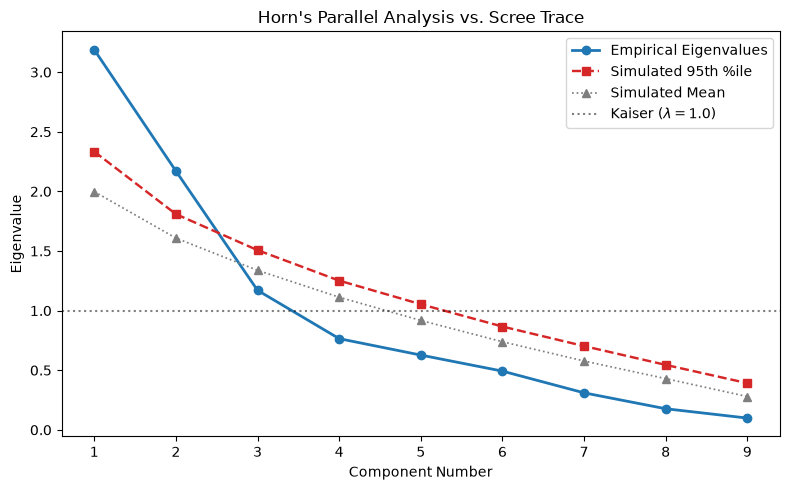

Horn's Parallel Analysis Eigenvalue Comparison:


,Empirical Eigenvalue,Synthetic (95th %ile),Synthetic (Mean),Retain
Component 1,3.188,2.333,1.998,Yes
Component 2,2.171,1.809,1.608,Yes
Component 3,1.170,1.507,1.338,No
Component 4,0.765,1.252,1.112,No
Component 5,0.627,1.054,0.918,No
Component 6,0.493,0.867,0.739,No
Component 7,0.310,0.703,0.578,No
Component 8,0.177,0.545,0.430,No
Component 9,0.099,0.392,0.279,No


Optimal Factors Suggested by Parallel Analysis: 2


In [18]:

# =========================================================================
# STEP 4: Retention Diagnostics (Parallel Analysis & Scree Plot)
# =========================================================================
print("\n" + "=" * 70)
print("STEP 4: FACTOR RETENTION (HORN'S PARALLEL ANALYSIS & KAISER)")
print("=" * 70)

parallel_results = perform_horn_parallel_analysis(
    df=df_metrics,
    corr_matrix=poly_corr,
    n_simulations=1000,
    percentile=95.0,
    random_state=random_state,
    plot_comparison=True,
)
pipeline_results["parallel_analysis"] = parallel_results

print("Horn's Parallel Analysis Eigenvalue Comparison:")
display(parallel_results["comparison_table"].round(3))
print(f"Optimal Factors Suggested by Parallel Analysis: {parallel_results['n_factors_parallel']}")


In [19]:

# =========================================================================
# STEP 5: PCA with Direct Oblimin Rotation (Abels et al. Model)
# =========================================================================
print("\n" + "=" * 70)
print("STEP 5: PCA WITH DIRECT OBLIMIN ROTATION")
print("=" * 70)

# Fits target PCA using factor_analyzer (uses parallel analysis factor count if desired, or defaults to Kaiser)
retained_factors = parallel_results["n_factors_parallel"] if parallel_results["n_factors_parallel"] > 0 else None

retained_factors = 3

pca_results = perform_abels_pca_oblimin(
    corr_matrix=poly_corr,
    n_factors=retained_factors,
    kaiser_cutoff=1.0,
    rotation="oblimin",
)
pipeline_results["pca"] = pca_results

print("Variance Explained Breakdown:")
display(pca_results["variance_summary"].round(2))

print("\nRotated Pattern Matrix (Table 3 Style):")
display(pca_results["pattern_loadings"].round(3))

print("\nStructure Matrix (Table 4 Style):")
display(pca_results["structure_matrix"].round(3))

print("\nComponent Correlations (Phi):")
display(pca_results["factor_correlations"].round(3))



STEP 5: PCA WITH DIRECT OBLIMIN ROTATION
Variance Explained Breakdown:


,Eigenvalue,% of Variance,Cumulative %
Component 1,3.19,35.42,35.42
Component 2,2.17,24.12,59.54
Component 3,1.17,13.00,72.54
Component 4,0.76,8.50,81.04
Component 5,0.63,6.97,88.01
Component 6,0.49,5.47,93.48
Component 7,0.31,3.45,96.93
Component 8,0.18,1.97,98.90
Component 9,0.10,1.10,100.00



Rotated Pattern Matrix (Table 3 Style):


,Component 1,Component 2,Component 3
Chain of Custody,-0.829,-0.029,-0.148
Authenticity,-0.876,0.123,-0.055
Integrity,-0.927,-0.139,0.322
Reliability,-0.038,0.122,0.703
Lawful Acquisition,-0.173,0.833,-0.112
Fact vs Inference,0.409,0.505,0.384
Competence and Qualification,0.138,0.687,0.346
Repeatability and reproducibility,-0.083,-0.028,0.874
Privacy compliance,-0.693,0.483,-0.166



Structure Matrix (Table 4 Style):


,Component 1,Component 2,Component 3
Chain of Custody,-0.844,0.045,-0.253
Authenticity,-0.896,0.211,-0.150
Integrity,-0.873,-0.007,0.193
Reliability,0.036,0.197,0.710
Lawful Acquisition,-0.276,0.840,-0.049
Fact vs Inference,0.402,0.500,0.486
Competence and Qualification,0.107,0.707,0.433
Repeatability and reproducibility,0.028,0.069,0.861
Privacy compliance,-0.765,0.541,-0.203



Component Correlations (Phi):


,Component 1,Component 2,Component 3
Component 1,1.000,-0.108,0.123
Component 2,-0.108,1.000,0.101
Component 3,0.123,0.101,1.000


In [20]:
# =========================================================================
# STEP 6: Scale Internal Consistency & Reliability
# =========================================================================
print("\n" + "=" * 70)
print("STEP 6: ORDINAL SCALE RELIABILITY & COMPOSITE RELIABILITY")
print("=" * 70)

reliability = compute_ordinal_reliability(
    df=df_metrics,
    poly_corr_matrix=poly_corr,
    n_bootstraps=n_bootstraps,
    alpha_ci=0.05,
    random_state=random_state,
)
pipeline_results["reliability"] = reliability

print(
    f"Ordinal Cronbach's Alpha: {reliability['ordinal_cronbach_alpha']:.3f} | 95% CI: [{reliability['ordinal_alpha_ci_95'][0]:.3f}, {reliability['ordinal_alpha_ci_95'][1]:.3f}]"
)
print(
    f"McDonald's Omega (Composite): {reliability['composite_reliability_omega']:.3f} | 95% CI: [{reliability['omega_ci_95'][0]:.3f}, {reliability['omega_ci_95'][1]:.3f}]"
)
print(
    f"Standard Cronbach's Alpha: {reliability['standard_cronbach_alpha']:.3f} | 95% CI: [{reliability['standard_alpha_ci_95'][0]:.3f}, {reliability['standard_alpha_ci_95'][1]:.3f}]"
)

print("\nSingle-Factor CFA Standardized Loadings (Unidimensional Model):")
display(reliability["single_factor_loadings"].round(3))

print("\nCronbach's Alpha if Item Omitted:")
display(reliability["alpha_if_dropped"].round(3))

print("\nMcDonald's Omega if Item Omitted:")
display(reliability["omega_if_dropped"].round(3))

print("\nCombined Item-Dropped Diagnostic Summary:")
display(reliability["item_dropped_summary"].round(3))


STEP 6: ORDINAL SCALE RELIABILITY & COMPOSITE RELIABILITY
Ordinal Cronbach's Alpha: 0.662 | 95% CI: [0.468, 0.834]
McDonald's Omega (Composite): 0.617 | 95% CI: [0.083, 0.876]
Standard Cronbach's Alpha: 0.723 | 95% CI: [0.539, 0.854]

Single-Factor CFA Standardized Loadings (Unidimensional Model):


,Standardized_Loading (λ),Error_Variance (θ)
Chain of Custody,0.844,0.287
Authenticity,0.901,0.188
Integrity,0.797,0.364
Reliability,-0.111,0.988
Lawful Acquisition,0.388,0.849
Fact vs Inference,-0.382,0.854
Competence and Qualification,-0.065,0.996
Repeatability and reproducibility,-0.145,0.979
Privacy compliance,0.832,0.307



Cronbach's Alpha if Item Omitted:


,Standard_Alpha_If_Dropped,Ordinal_Alpha_If_Dropped,Delta_Ordinal_Alpha
Item,,,
Chain of Custody,0.711,0.643,-0.019
Authenticity,0.671,0.601,-0.062
Integrity,0.672,0.597,-0.066
Reliability,0.709,0.664,0.001
Lawful Acquisition,0.687,0.611,-0.051
Fact vs Inference,0.727,0.693,0.031
Competence and Qualification,0.674,0.639,-0.024
Repeatability and reproducibility,0.754,0.664,0.002
Privacy compliance,0.678,0.587,-0.075



McDonald's Omega if Item Omitted:


,Omega_If_Dropped,Delta_Omega
Item,,
Chain of Custody,0.617,0.000
Authenticity,0.319,-0.298
Integrity,0.345,-0.272
Reliability,0.690,0.073
Lawful Acquisition,0.520,-0.098
Fact vs Inference,0.749,0.132
Competence and Qualification,0.679,0.062
Repeatability and reproducibility,0.698,0.081
Privacy compliance,0.205,-0.412



Combined Item-Dropped Diagnostic Summary:


,Standard_Alpha_If_Dropped,Ordinal_Alpha_If_Dropped,Delta_Ordinal_Alpha,Omega_If_Dropped,Delta_Omega
Item,,,,,
Chain of Custody,0.711,0.643,-0.019,0.617,0.000
Authenticity,0.671,0.601,-0.062,0.319,-0.298
Integrity,0.672,0.597,-0.066,0.345,-0.272
Reliability,0.709,0.664,0.001,0.690,0.073
Lawful Acquisition,0.687,0.611,-0.051,0.520,-0.098
Fact vs Inference,0.727,0.693,0.031,0.749,0.132
Competence and Qualification,0.674,0.639,-0.024,0.679,0.062
Repeatability and reproducibility,0.754,0.664,0.002,0.698,0.081
Privacy compliance,0.678,0.587,-0.075,0.205,-0.412



STEP 7: PRE-CLUSTERING TRIANGULATION (SILHOUETTE, GAP STATISTIC, WARD)


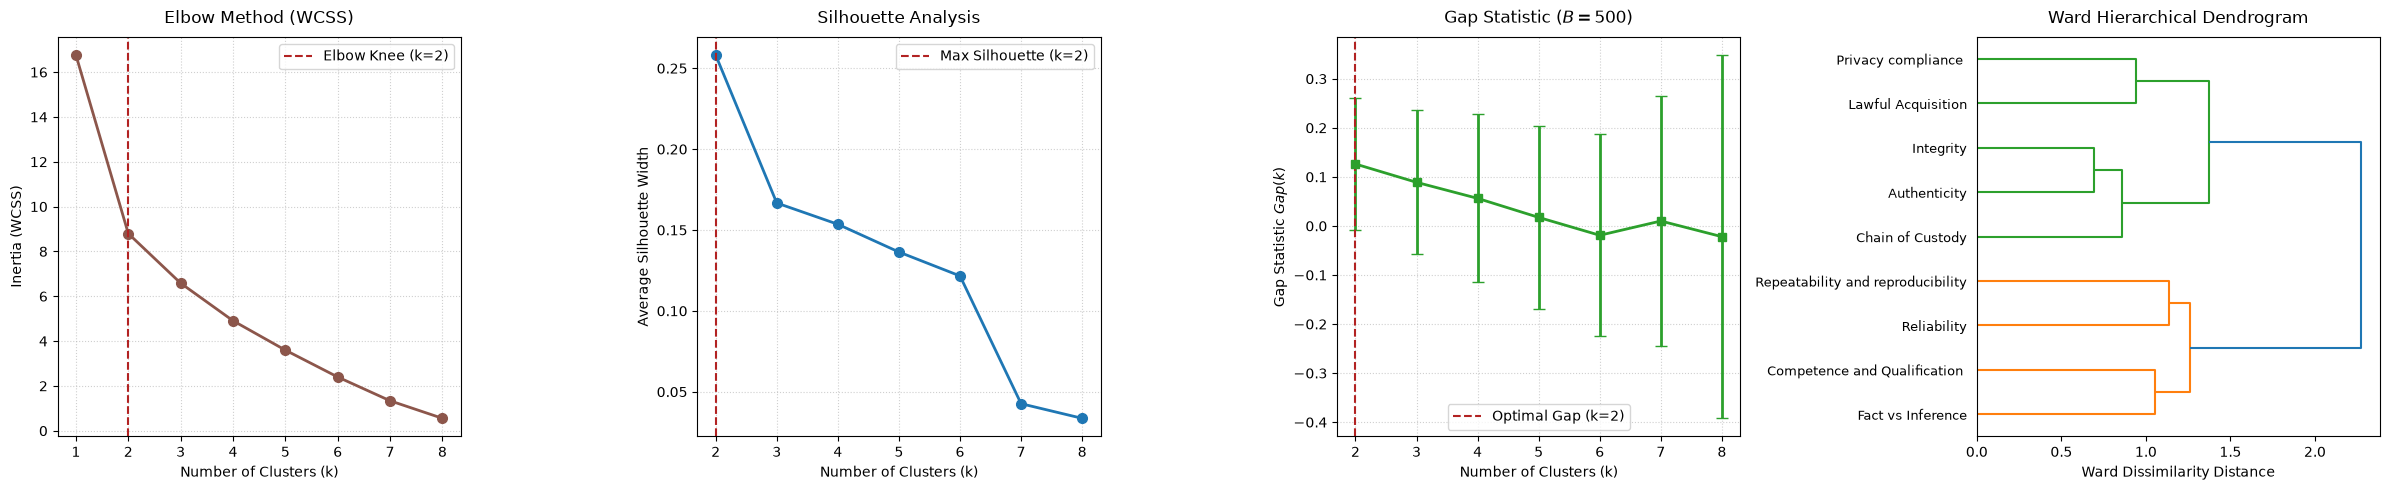

Triangulation Diagnostics Summary:


,Inertia (Elbow WCSS),Silhouette Score,Gap Statistic,Gap Std Error
k = 2,8.797,0.258,0.126,0.135
k = 3,6.584,0.167,0.089,0.146
k = 4,4.908,0.154,0.056,0.171
k = 5,3.596,0.136,0.017,0.187
k = 6,2.398,0.122,-0.019,0.206
k = 7,1.337,0.043,0.010,0.254
k = 8,0.554,0.034,-0.022,0.370


In [21]:

# =========================================================================
# STEP 7: Compute Pre-Clustering Triangulation
# =========================================================================
print("\n" + "=" * 70)
print("STEP 7: PRE-CLUSTERING TRIANGULATION (SILHOUETTE, GAP STATISTIC, WARD)")
print("=" * 70)

clustering_triangulation = compute_pre_clustering_triangulation(
    poly_corr_matrix=poly_corr,
    k_range=range(2, 10),
    n_bootstraps_gap=500,
    random_state=random_state,
    plot_results=True,
)
pipeline_results["clustering_triangulation"] = clustering_triangulation

print("Triangulation Diagnostics Summary:")
display(clustering_triangulation["triangulation_table"].round(3))


In [22]:
# =========================================================================
# STEP 7.5: Compute Pre-Clustering NBClust
# =========================================================================
print("\n" + "=" * 70)
print("STEP 7.5: PRE-CLUSTERING NBCLUST (MAJORITY VOTING)")
print("=" * 70)

clustering_nbclust = run_nbclust_via_rscript(
    data=df_metrics,
    min_nc=2,
    max_nc=8,
    method="kmeans",
    distance="euclidean",
    index="alllong",
)

pipeline_results["clustering_nbclust"] = clustering_nbclust

print(f"Optimal k Proposed by Majority Rule: k = {clustering_nbclust['optimal_k']}")

print("\nVote Tally Across Valid Indices:")
for k_val, count in sorted(clustering_nbclust["votes_per_k"].items()):
    print(f"  k = {k_val}: {count} votes")

print("\nIndex-by-Index Best Criterion Summary:")
display(clustering_nbclust["best_nc_summary"])

print("\nDetailed Internal Indices Table Across Tested k:")
display(clustering_nbclust["all_indices_table"].round(3))


STEP 7.5: PRE-CLUSTERING NBCLUST (MAJORITY VOTING)
Optimal k Proposed by Majority Rule: k = 2

Vote Tally Across Valid Indices:
  k = 2: 8 votes
  k = 3: 3 votes
  k = 4: 2 votes
  k = 6: 7 votes
  k = 7: 3 votes

Index-by-Index Best Criterion Summary:


,KL,CH,Hartigan,CCC,Scott,Marriot,TrCovW,TraceW,Friedman,Rubin,...,Frey,McClain,Gamma,Gplus,Tau,Dunn,Hubert,SDindex,Dindex,SDbw
Number_clusters,6.000,2.0000,6.0000,2.0000,4.0000,4.0000,3.0000,6.0000,6.0000,6.0000,...,1.0,2.0000,7.0000,7.0000,-inf,0.3333,0,1.7367,0,0.3931
Value_Index,8.316,9.9572,4.7775,5.3821,86.4701,176042.1223,41.8172,5.8547,1964.5071,-2.6225,...,NaN,0.5373,0.8044,4.8148,5.0,0.0000,7,0.0000,6,6.0000



Detailed Internal Indices Table Across Tested k:


,KL,CH,Hartigan,CCC,Scott,Marriot,TrCovW,TraceW,Friedman,Rubin,...,Frey,McClain,Gamma,Gplus,Tau,Dunn,Hubert,SDindex,Dindex,SDbw
2,1.314,9.957,7.132,5.382,150.948,454000.639,97.013,65.560,768.798,7.557,...,0.870,0.537,0.600,17.963,NaN,0.294,0.023,2.131,1.402,1.078
3,1.457,9.529,5.042,4.038,195.680,206739.769,55.196,51.448,649.862,9.630,...,0.680,1.134,0.620,15.574,NaN,0.250,0.030,2.300,1.249,0.840
4,1.001,8.942,4.893,3.802,282.150,16753.528,36.168,42.813,1158.709,11.573,...,-0.131,1.700,0.642,12.259,NaN,0.250,0.029,2.062,1.119,0.675
5,0.816,8.909,6.155,3.868,344.644,2809.409,25.626,35.563,1655.394,13.932,...,0.073,1.702,0.682,10.690,NaN,0.333,0.031,1.816,1.017,0.480
6,8.316,9.820,1.378,4.468,377.130,1267.962,13.604,28.055,3619.902,17.660,...,0.583,1.908,0.780,6.474,NaN,0.281,0.034,1.802,0.914,0.393
7,0.414,8.519,2.133,3.588,409.687,539.543,16.171,26.402,2847.114,18.766,...,1.252,2.407,0.804,4.815,NaN,0.268,0.035,1.737,0.886,0.418



STEP 8: PUBLICATION PROJECTION & CLUSTERING


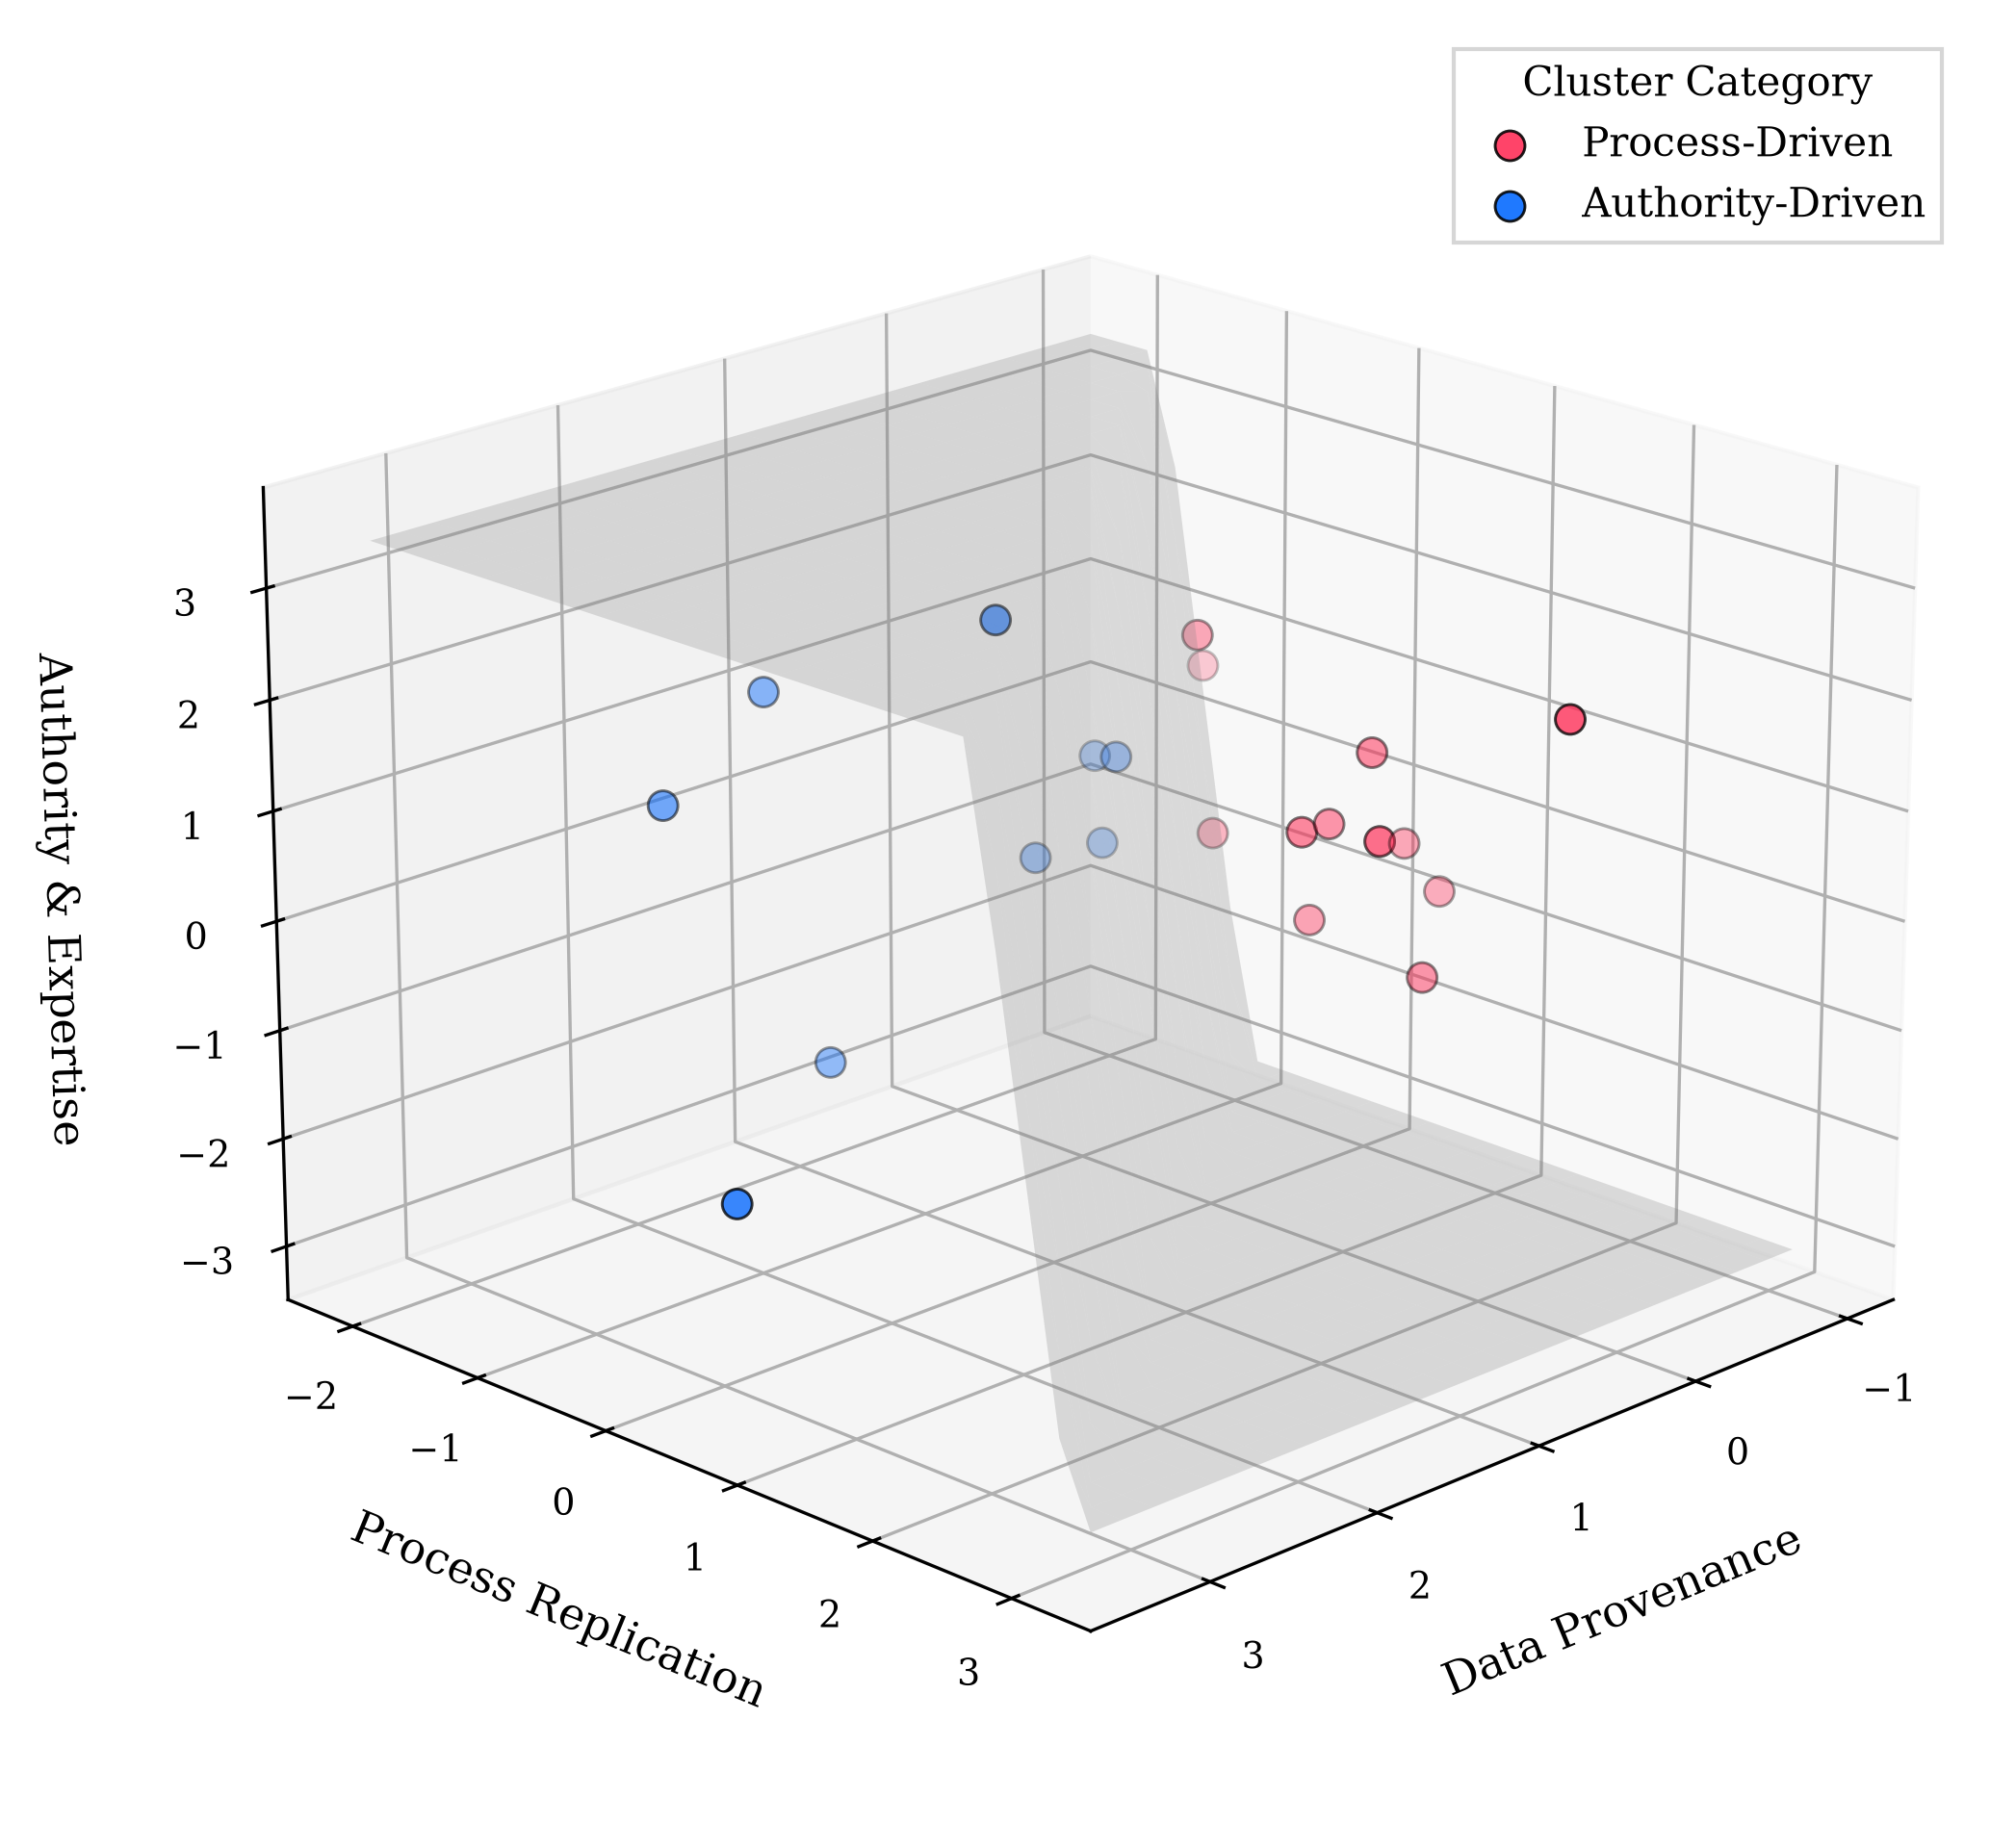

Cluster Assignments (k=2):


,Publication,Assigned_Cluster,Data Provenance,Process Replication,Authority & Expertise
Burri_2020,Burri_2020,Authority-Driven,-3.290543e-01,-1.303562e+00,4.182268e-02
Balmiki_2023,Balmiki_2023,Authority-Driven,-2.575049e-01,-1.157998e+00,-6.922805e-01
Akbarfam_2023,Akbarfam_2023,Process-Driven,-4.972977e-01,1.117722e+00,-3.317689e-01
Ahmad_2020,Ahmad_2020,Process-Driven,-6.904377e-01,-8.992193e-01,8.814265e-01
Lusetti_2020,Lusetti_2020,Process-Driven,-5.959254e-01,3.780831e-02,-1.100813e+00
Li_2019,Li_2019,Process-Driven,-6.674748e-01,-1.077555e-01,-3.667094e-01
Li_2023,Li_2023,Process-Driven,-6.416082e-01,8.362017e-01,-1.329311e+00
Kumar_2021,Kumar_2021,Process-Driven,-6.416082e-01,8.362017e-01,-1.329311e+00
Jacob_2022,Jacob_2022,Process-Driven,-5.959254e-01,3.780831e-02,-1.100813e+00
Harding_2024,Harding_2024,Process-Driven,8.022432e-02,-2.648045e-02,1.859102e+00



Mean Metric Profiles (0-2 Scale) Across Clusters:


,Chain of Custody,Authenticity,Integrity,Reliability,Lawful Acquisition,Fact vs Inference,Competence and Qualification,Repeatability and reproducibility,Privacy compliance
Assigned_Cluster,,,,,,,,,
Authority-Driven,1.22,1.22,1.56,1.00,0.22,0.33,0.00,0.89,0.56
Process-Driven,1.93,1.93,1.99,1.16,1.15,0.33,0.55,1.00,1.87


In [28]:

# =========================================================================
# STEP 8: Project & Cluster Publications
# =========================================================================
print("\n" + "=" * 70)
print("STEP 8: PUBLICATION PROJECTION & CLUSTERING")
print("=" * 70)

optimal_k = clustering_triangulation["optimal_k_silhouette"]

pca_clusters = project_and_cluster_publications(
    df_metrics=df_metrics,
    pca_results=pipeline_results["pca"],
    n_clusters=2,
    clustering_method="kmeans",
    publication_labels=pub_labels,
    random_state=random_state,
    plot_scatter=True,
    save_path="/home/david/Git/SDLT_Number_Crunching/Images/pca_plot.pdf"
)
pipeline_results["publication_clusters"] = pca_clusters

print(f"Cluster Assignments (k={optimal_k}):")
display(pca_clusters["clustered_publications"])

print(f"\nMean Metric Profiles (0-2 Scale) Across Clusters:")
display(pca_clusters["cluster_metric_profiles"].round(2))

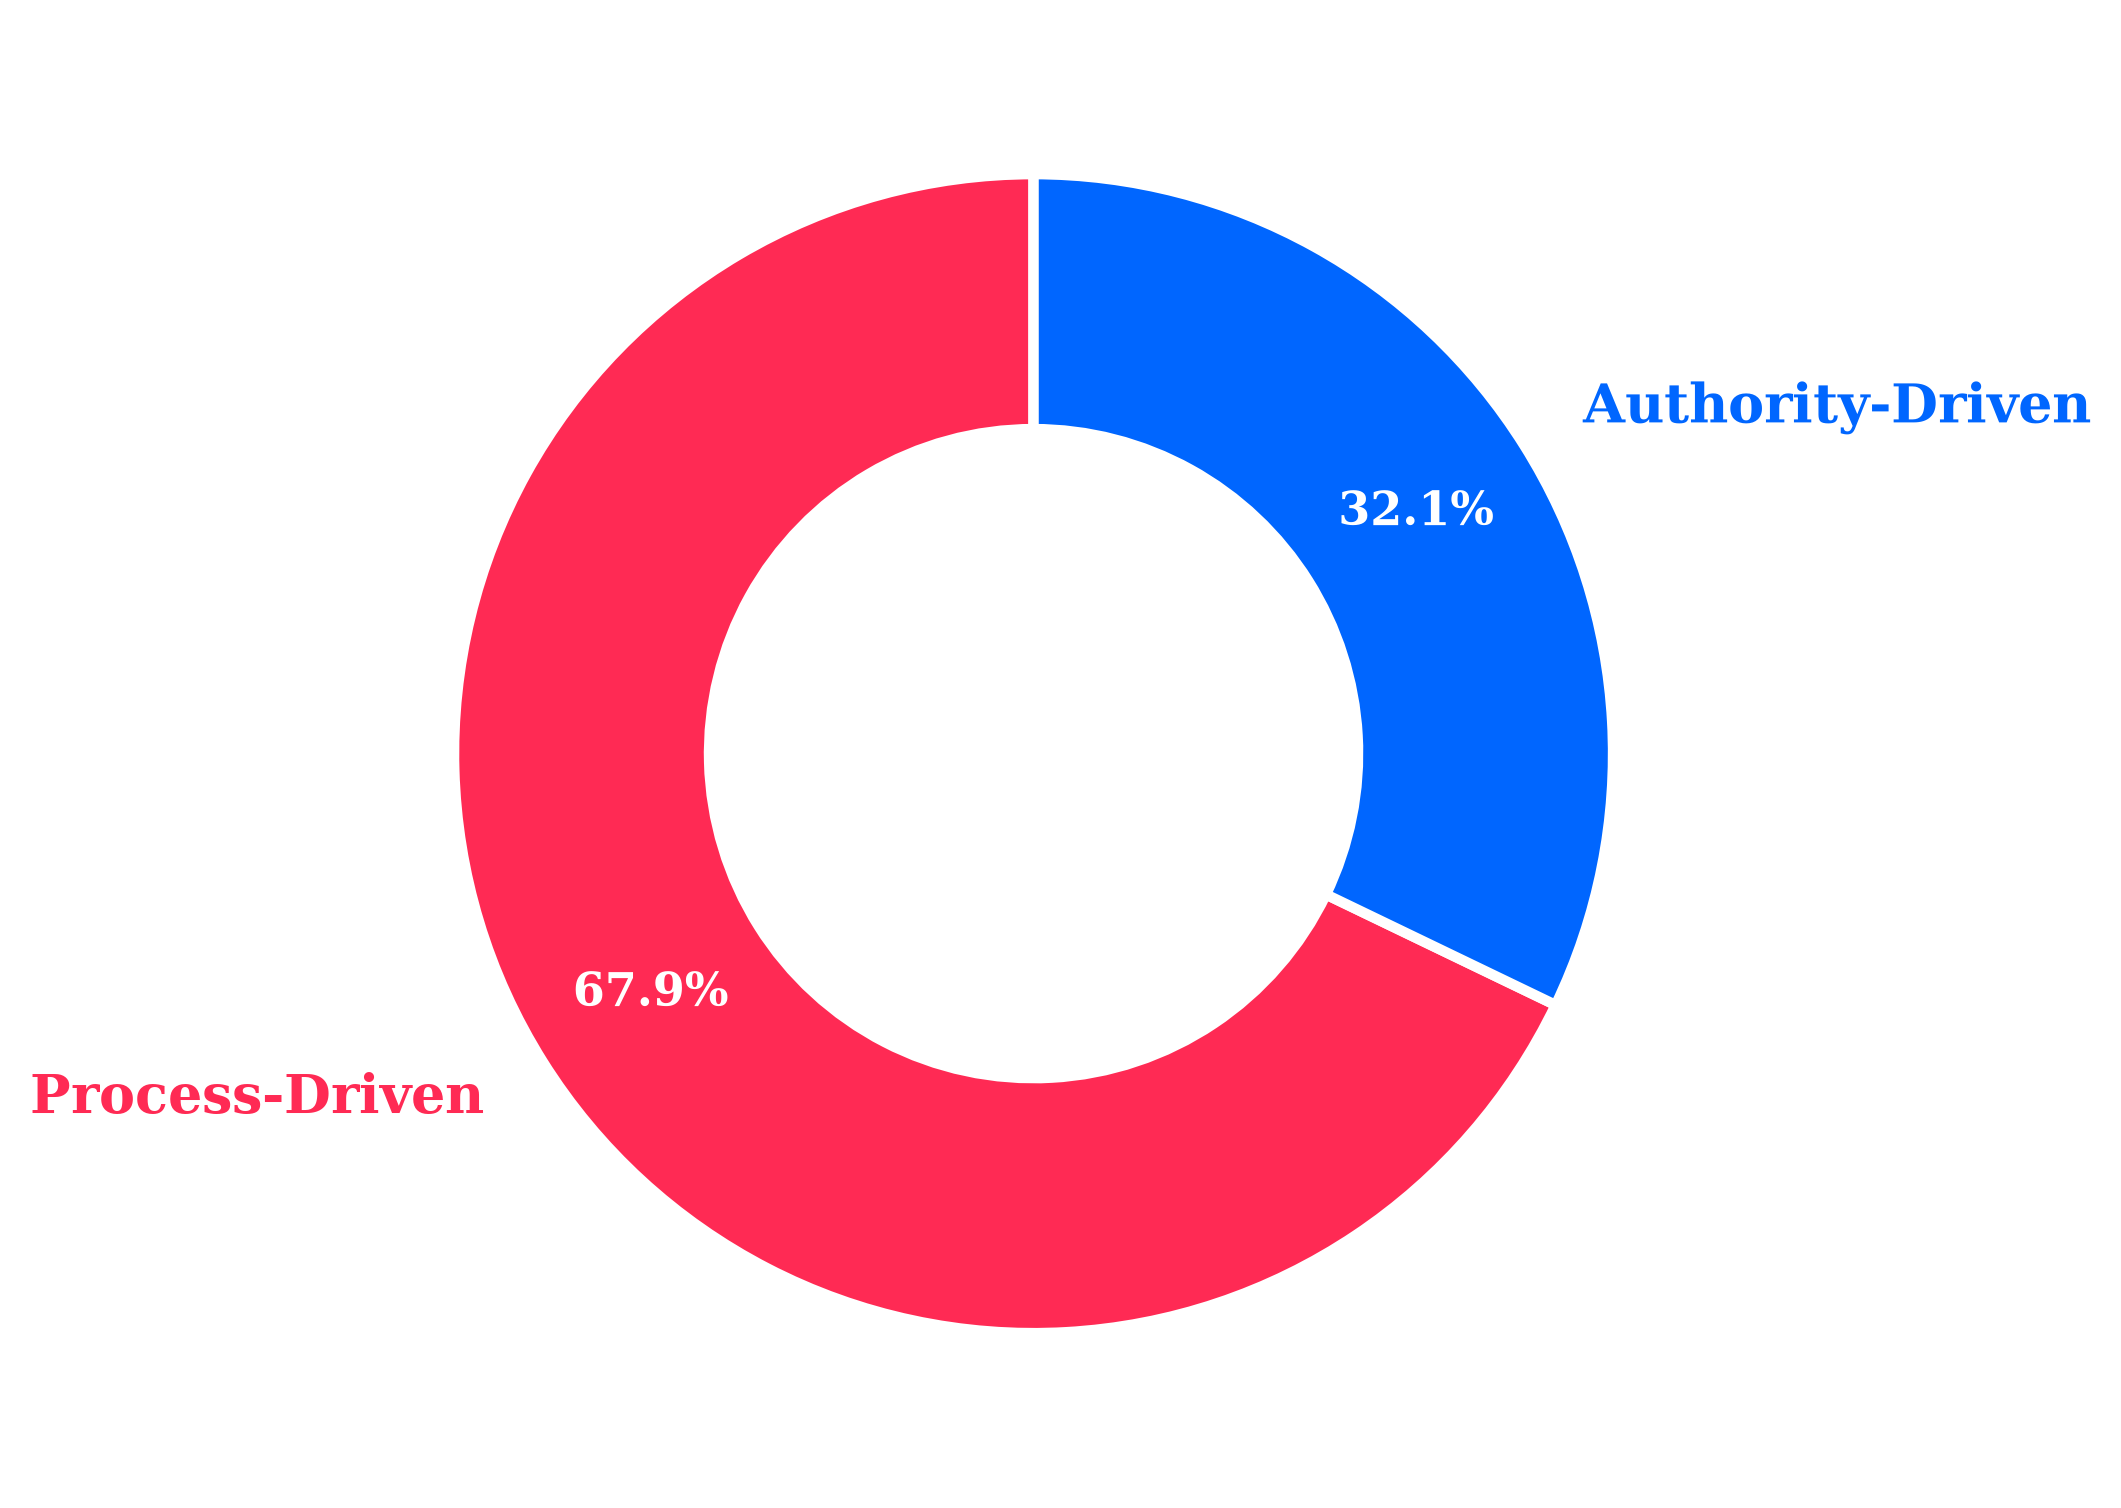

In [25]:
# Count the occurrences of each cluster
df = pca_clusters["clustered_publications"]
cluster_counts = df["Assigned_Cluster"].value_counts()

# Define explicit, vibrant blue and red mapping
color_map = {
    "Authority-Driven": "#0066FF",  # Vivid, eye-catching electric blue
    "Process-Driven": "#FF2A54"     # Bright, high-contrast vivid red
}
colors = [color_map.get(cluster, "#333333") for cluster in cluster_counts.index]

fig, ax = plt.subplots(figsize=(7, 7))

# Plot donut chart
wedges, texts, autotexts = ax.pie(
    cluster_counts,
    labels=cluster_counts.index,
    colors=colors,
    autopct="%1.1f%%",
    pctdistance=0.78,
    labeldistance=1.12,
    startangle=90,
    wedgeprops={
        "width": 0.44,
        "edgecolor": "white",
        "linewidth": 2.5
    }
)

# Match outer label text colors to slice colors
for text, color in zip(texts, colors):
    text.set_color(color)
    text.set_fontsize(13)
    text.set_weight("bold")

# Style inner percentage text
for autotext in autotexts:
    autotext.set_color("white")
    autotext.set_fontsize(11)
    autotext.set_weight("bold")

plt.tight_layout()
plt.show()

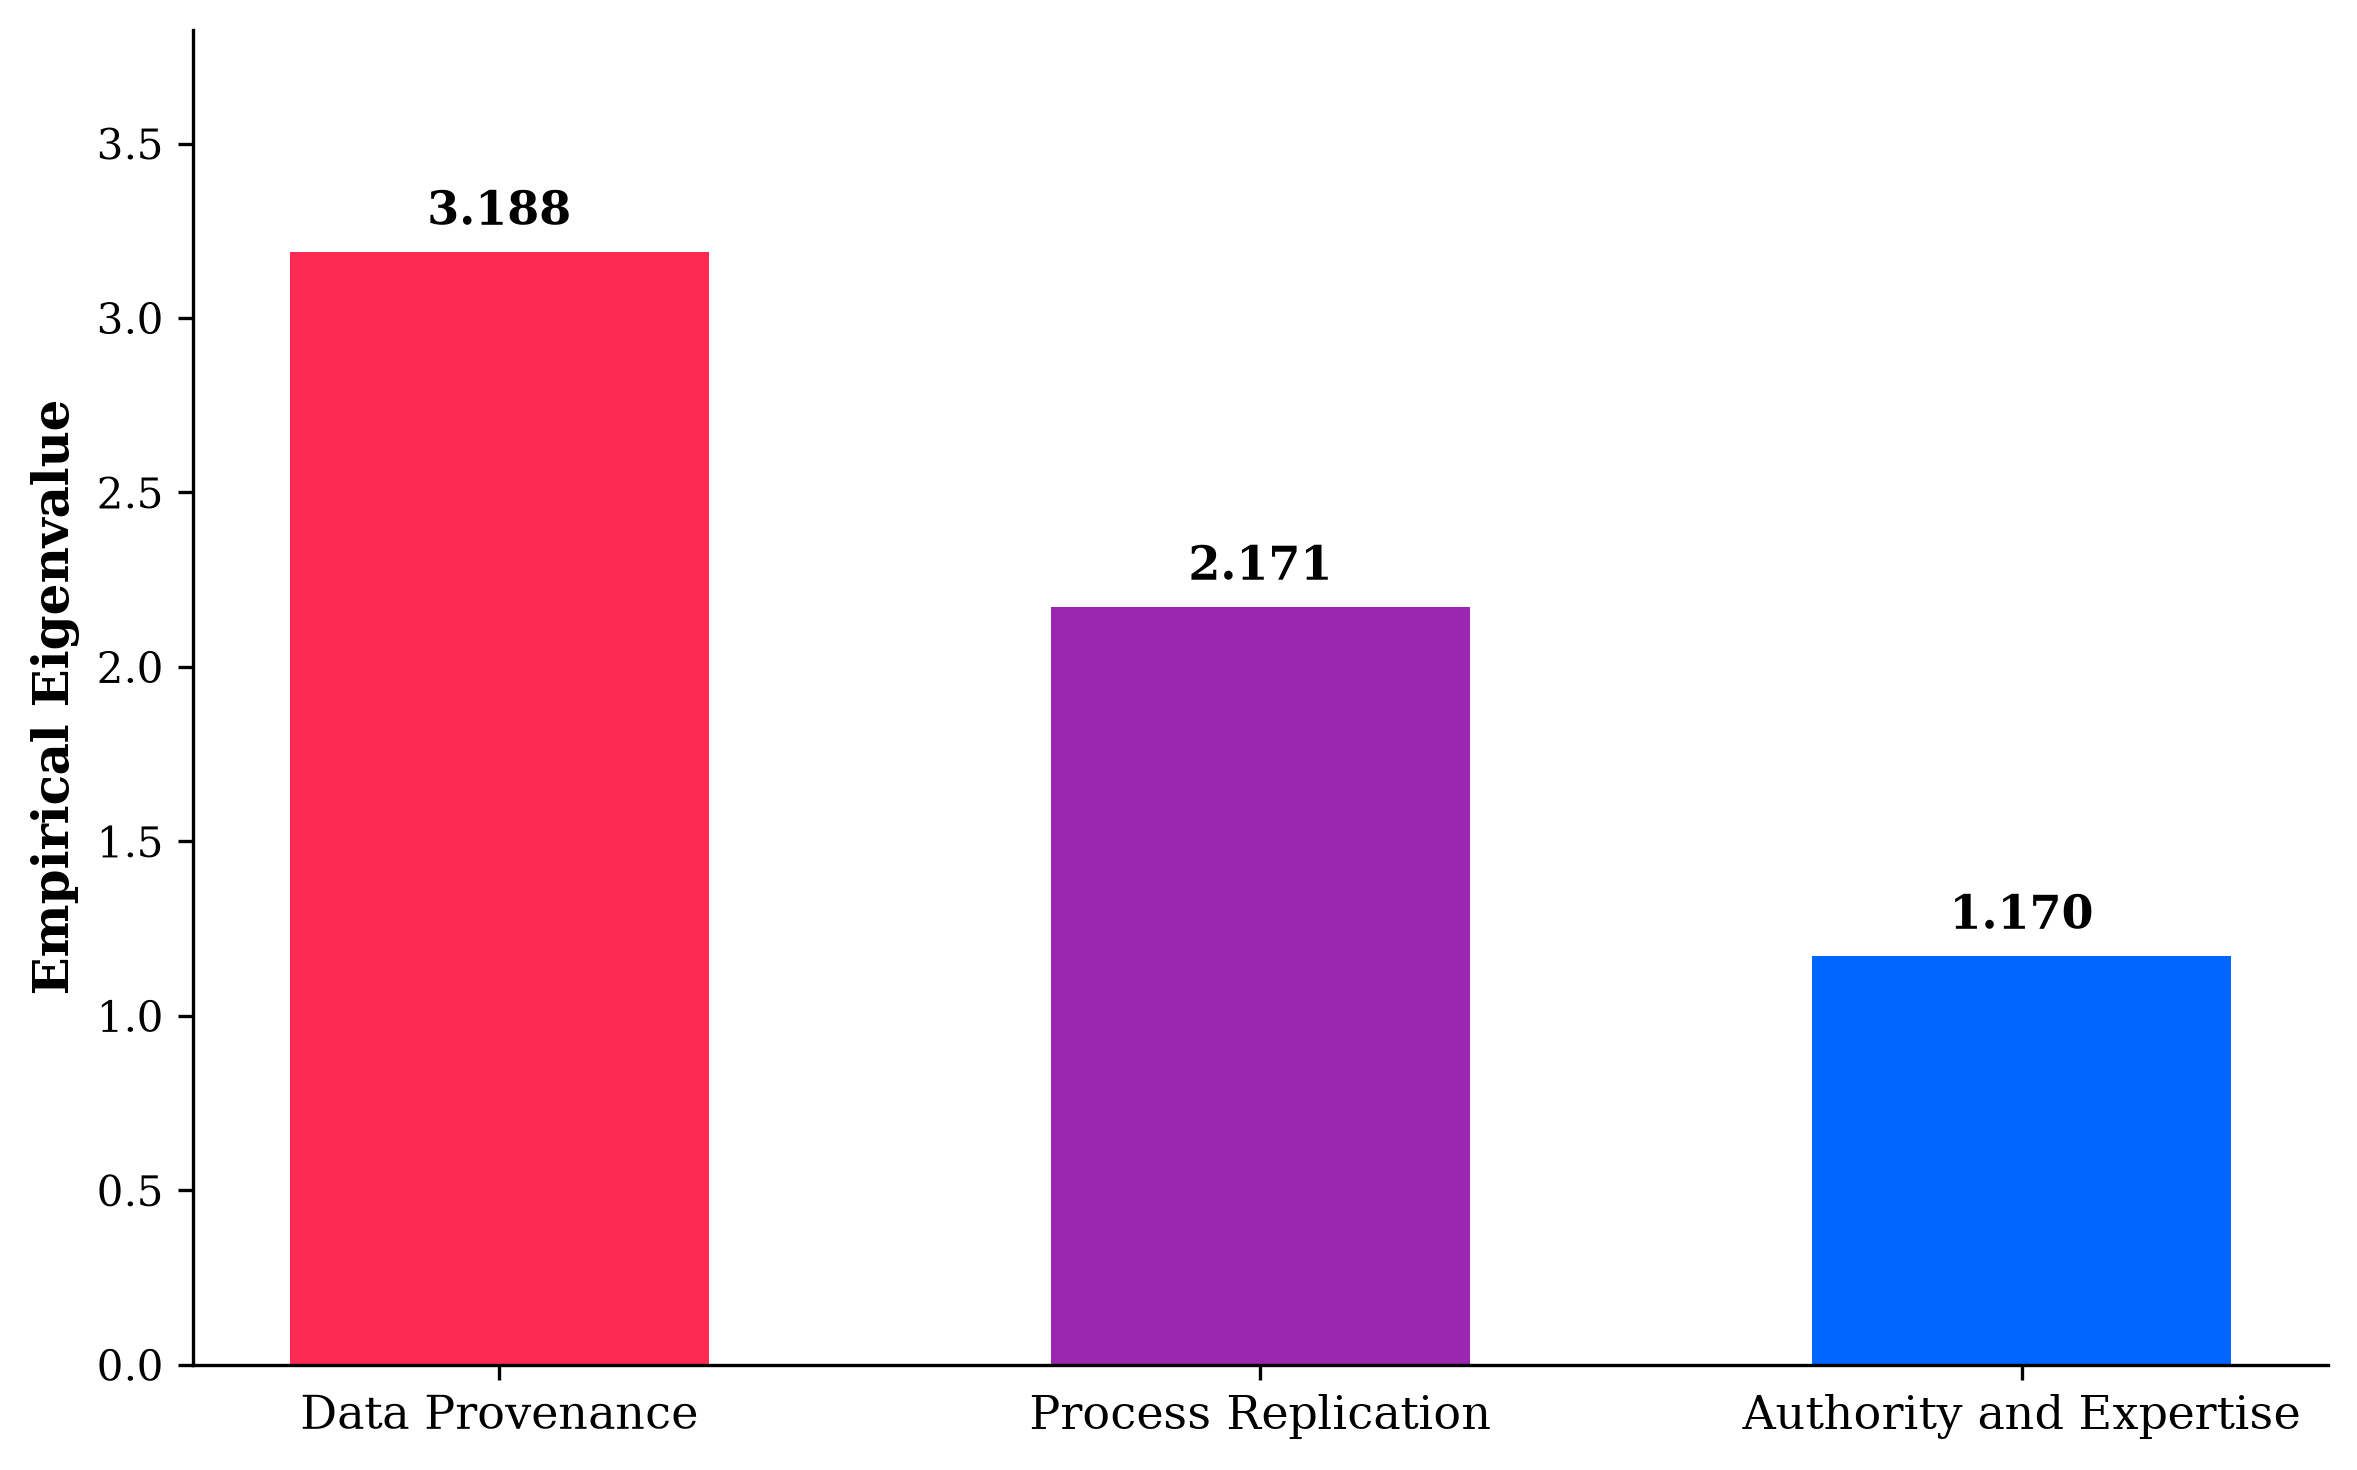

In [26]:
# Extract the first 3 eigenvalues from the dataframe
eigenvalues = parallel_results["comparison_table"]["Empirical Eigenvalue"].iloc[:3]

# Define component labels and corresponding colors
components = ["Data Provenance", "Process Replication", "Authority and Expertise"]
colors = [ "#FF2A54", "#9B27B0", "#0066FF"]

fig, ax = plt.subplots(figsize=(8, 5))

# Create the bar chart
bars = ax.bar(components, eigenvalues, color=colors, width=0.55)

# Display exact eigenvalue values above each bar
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.3f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Formatting and clean aesthetic
ax.set_ylabel("Empirical Eigenvalue", fontsize=12, fontweight="bold")
ax.set_ylim(0, max(eigenvalues) * 1.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", labelsize=11)
ax.tick_params(axis="y", labelsize=10)

plt.tight_layout()
plt.show()